# 01 · Explore the BTS flight data (one month: July 2025)

**Goal (CLAUDE.md, Phase 1, step 1.2):** understand the flight table before building anything on it.
We use **one month only** (July 2025): it is big enough to see real patterns and small enough to run fast.

Rules used in this notebook:
- The raw ZIP is read directly from `data_dir` (outside the repo). **Nothing is written to disk.**
- Time columns are read **as text** (`"0659"` must not become `659`).
- The delay-cause columns are only **looked at** here. They are known after the flight, so they are **never model inputs**.

## 0. Setup

**What:** import the libraries and read `config.yaml` to find the data folder and the 10 hubs.
**Why:** paths are never written by hand in the code, so the same notebook works on another PC by changing only `config.yaml`.

In [1]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

# The notebook runs from notebooks/, config.yaml sits one folder up (the repo root).
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load((REPO / "config.yaml").read_text(encoding="utf-8"))

HUBS = cfg["hubs"]
BTS_ZIP = Path(cfg["data_dir"]) / "raw" / "bts" / "bts_2025_07.zip"
print("hubs:", HUBS)
print("file:", BTS_ZIP, "| exists:", BTS_ZIP.exists())

hubs: ['ATL', 'ORD', 'DFW', 'DEN', 'LAX', 'JFK', 'CLT', 'LAS', 'PHX', 'SEA']
file: C:\data\flight-delay\raw\bts\bts_2025_07.zip | exists: True


**What:** read the month. The ZIP holds a CSV **and** a `readme.html`, so we open the `.csv` member by name.
We read only the columns we need (110 exist), and the 4 clock-time columns as text.

**Why:** fewer columns = less memory and faster. Text times keep the leading zero (`"0659"`), which we need later to build real timestamps.

In [2]:
TIME_COLS = ["CRSDepTime", "DepTime", "CRSArrTime", "ArrTime"]   # HHMM local clock times
COLS = [
    "FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline", "Tail_Number",
    "Origin", "Dest", "OriginAirportID", "DestAirportID",
    *TIME_COLS, "CRSElapsedTime",
    "DepDelay", "DepDel15", "ArrDelay", "ArrDel15", "Cancelled", "Diverted",
    "CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay",
]


def read_bts_month(zip_path: Path, columns: list[str]) -> pd.DataFrame:
    """Read the CSV inside one BTS monthly ZIP (not the readme), time columns as strings."""
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
        with zf.open(csv_name) as f:
            return pd.read_csv(f, usecols=columns, dtype={c: str for c in TIME_COLS},
                               low_memory=False)


df = read_bts_month(BTS_ZIP, COLS)
df["FlightDate"] = pd.to_datetime(df["FlightDate"], format="%Y-%m-%d")   # explicit format
print("shape:", df.shape)
print(f"memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
df.head()

shape: (631428, 24)
memory: 140 MB


,FlightDate,Reporting_Airline,Tail_Number,Flight_Number_Reporting_Airline,OriginAirportID,Origin,DestAirportID,Dest,CRSDepTime,DepTime,...,ArrDelay,ArrDel15,Cancelled,Diverted,CRSElapsedTime,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2025-07-23,AA,N450AN,969,13303,MIA,11057,CLT,0832,0829,...,-5.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN
1,2025-07-24,AA,N431AN,969,13303,MIA,11057,CLT,0832,0957,...,74.0,1.0,0.0,0.0,130.0,0.0,0.0,0.0,0.0,74.0
2,2025-07-25,AA,N444UW,969,13303,MIA,11057,CLT,0832,0828,...,-18.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN
3,2025-07-26,AA,N462AA,969,13303,MIA,11057,CLT,0832,0827,...,10.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN
4,2025-07-27,AA,N458AL,969,13303,MIA,11057,CLT,0832,0836,...,-13.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN


**What:** compare the number of rows with the count found during the download check (631,428).
**Why:** a different number would mean the file was read wrongly (wrong member, cut file, bad parsing).

In [3]:
EXPECTED_ROWS = 631_428
print(f"rows read: {len(df):,} | expected: {EXPECTED_ROWS:,} | match: {len(df) == EXPECTED_ROWS}")
print("dates:", df["FlightDate"].min().date(), "->", df["FlightDate"].max().date())
print("time column types:", df[TIME_COLS].dtypes.unique())

rows read: 631,428 | expected: 631,428 | match: True
dates: 2025-07-01 -> 2025-07-31
time column types: [<StringDtype(na_value=nan)>]


**Question:** Does the row count match 631,428? If one day it does not, what are 2 possible reasons?

**My answer:**
the reasons are about reading the file:

The download was cut off (incomplete ZIP), or the wrong file/member was opened (e.g. the readme instead of the CSV).
Parsing problems: wrong separator, a quote character breaking lines, rows skipped by an option.
BTS republished the month with corrections (rare, but it happens).
A filter was applied by mistake (dates, airports).


## 1. Counts: flights, airlines, airports, hubs

**What:** how many flights, airlines and departure airports, and how many flights leave from our 10 hubs.
**Why:** our scope is "flights departing from the 10 hubs". We need to know how much of the US traffic that keeps.

In [4]:
from_hub = df["Origin"].isin(HUBS)
summary = pd.Series({
    "flights": len(df),
    "airlines (Reporting_Airline)": df["Reporting_Airline"].nunique(),
    "origin airports": df["Origin"].nunique(),
    "flights from the 10 hubs": int(from_hub.sum()),
    "share from the 10 hubs (%)": round(100 * from_hub.mean(), 1),
})
summary.to_frame("value")

,value
flights,631428.0
airlines (Reporting_Airline),14.0
origin airports,345.0
flights from the 10 hubs,208298.0
share from the 10 hubs (%),33.0


**What:** flights per hub, as a bar chart.
**Why:** hubs are not equal: a big hub gives the model many more examples than a small one.

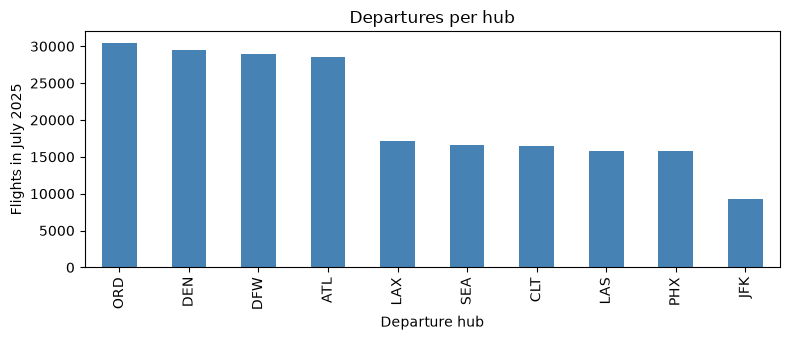

In [5]:
per_hub = df.loc[from_hub, "Origin"].value_counts()
ax = per_hub.plot.bar(figsize=(8, 3.5), color="steelblue")
ax.set_xlabel("Departure hub")
ax.set_ylabel("Flights in July 2025")
ax.set_title("Departures per hub")
plt.tight_layout()
plt.show()

**Question:** What share of all US domestic flights leaves from our 10 hubs? Is one month of it enough data to train on, or why do we need 2024–2025?

**My answer:**
the hubs were chosen because they’re the biggest airports (most flights, most connections), not because of their states. Make the argument concrete: 208,298 hub flights in July means a lot of rows, but all from one season (summer thunderstorms). Winter snow, holidays and rare severe-weather days aren’t in July at all. Two years = each month seen twice and more rare storm days for the radar and text models.


## 2. Is there a unique key for a flight?

**What:** check that (date, airline, flight number, origin, scheduled departure) identifies exactly one row.
**Why:** every later join (weather, radar, previous leg) attaches data **to one flight**. If the key is not unique,
a join can silently duplicate rows. The Gold table test `test_no_duplicate_flights` depends on this.

In [6]:
KEY = ["FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline", "Origin", "CRSDepTime"]

dup = df.duplicated(KEY, keep=False)        # keep=False marks EVERY copy, not only the 2nd
print(f"rows sharing a key: {dup.sum():,} ({100 * dup.mean():.3f} %)")
df.loc[dup, KEY + ["Dest", "Tail_Number", "Cancelled"]].sort_values(KEY).head(10)

rows sharing a key: 0 (0.000 %)


,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,CRSDepTime,Dest,Tail_Number,Cancelled


**Question:** Is the key unique? If not, what do the duplicates look like, and what would you add to the key (or remove) to fix it?

**my answer** :0 rows share the key. But if there were duplicates, don’t drop them silently:

If two rows are completely identical, it’s a true duplicate. Remove it and count how many you removed.
If they share the key but differ (e.g. different Dest or Tail_Number), the key is incomplete: two different flights. The fix is to add a column to the key. That’s exactly why CRSDepTime is in it: an airline can use the same flight number twice in one day from the same airport (different times). Nice experiment: remove CRSDepTime from KEY, rerun, and see whether duplicates appear.

## 3. Cancelled, diverted and missing tail numbers

**What:** the share of flights that were cancelled, diverted, or have no tail number.
**Why:**
- cancelled flights have **no delay**: they can never be a delay label;
- diverted flights end at another airport: they break the aircraft's chain;
- without a tail number we cannot build the rotation (previous/next leg) at all.

In [7]:
tail = df["Tail_Number"].astype("string").str.strip()
shares = pd.Series({
    "cancelled": df["Cancelled"].eq(1).mean(),
    "diverted": df["Diverted"].eq(1).mean(),
    "missing tail number": (tail.isna() | tail.eq("")).mean(),
}) * 100
shares.round(2).to_frame("% of flights")

,% of flights
cancelled,2.45
diverted,0.50
missing tail number,0.27


**What:** are missing tail numbers mostly on cancelled flights?
**Why:** if the aircraft never flew, a missing tail is expected; on flown flights it is a real gap in the chain.

In [8]:
pd.crosstab(tail.isna() | tail.eq(""), df["Cancelled"].eq(1),
            rownames=["tail missing"], colnames=["cancelled"])

cancelled,False,True
tail missing,,
False,615955,13779
True,0,1694


**Question:** Why must cancelled flights never be used as a delay label? What happens to the rotation of a flight with no tail number?

Your answer: noise; drop flights with no tail; “all cancelled flights have no tail”. ❌ The table was misread.
Read the table again:

tail missing  cancelled=False  cancelled=True
False              615,955        13,779
True                     0         1,694
Cancelled flights: 13,779 + 1,694 = 15,473. Most of them (13,779) do have a tail number.
Every missing tail (1,694) is on a cancelled flight, and 0 flown flights have a missing tail.
So every flight that actually flew has a tail number, and rotations can be built for all flown flights. That’s excellent news for the project.

Correct answer:

A cancelled flight has no departure delay: DepDelay is empty, because the plane never left. It isn’t “noise”; it’s a different outcome (cancellation ≠ delay). Using it as a delay label would be wrong. Don’t delete it from the data, though: it’s needed to break the chain (the plane didn’t fly that leg, so the next leg can’t inherit a delay from it). It can also become a separate target later.
No tail number means no previous/next leg can be found. The flight stays in the data with has_previous_leg = False; you don’t drop it. Here this only concerns cancelled flights.

## 4. How are departure delays distributed?

**What:** histogram of `DepDelay` (minutes) for flights that were not cancelled. Two versions:
1. clipped to −30…180 min, normal scale: shows the bulk of flights;
2. full range, **log scale** on the counts: shows the rare, very long delays (the "long right tail").

**Why:** the shape tells us how to train. A long tail means a few huge delays can dominate the error → log transform or capping for regression (CLAUDE.md §11).
Negative values = the flight left **early**.

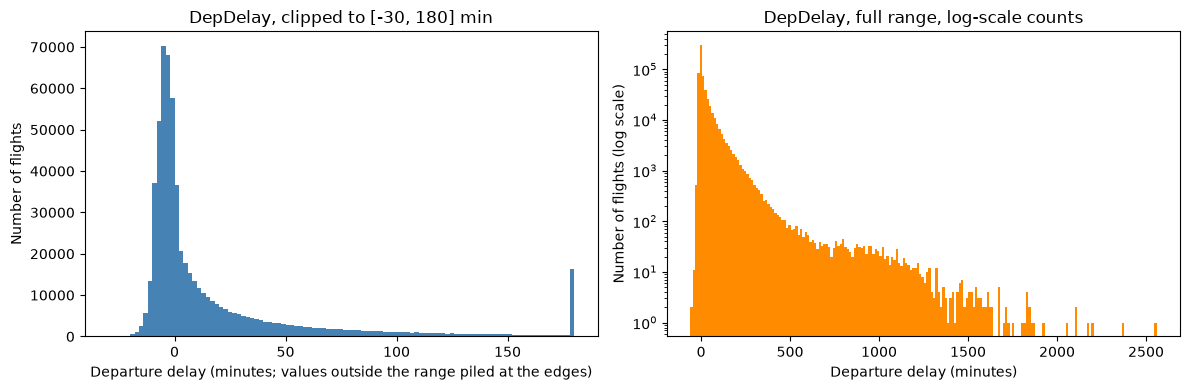

In [9]:
flown = df[df["Cancelled"].eq(0)]
dep = flown["DepDelay"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(dep.clip(-30, 180), bins=105, color="steelblue")
axes[0].set_title("DepDelay, clipped to [-30, 180] min")
axes[0].set_xlabel("Departure delay (minutes; values outside the range piled at the edges)")
axes[0].set_ylabel("Number of flights")

axes[1].hist(dep, bins=200, color="darkorange", log=True)
axes[1].set_title("DepDelay, full range, log-scale counts")
axes[1].set_xlabel("Departure delay (minutes)")
axes[1].set_ylabel("Number of flights (log scale)")
plt.tight_layout()
plt.show()

**What:** percentiles, mean vs. median, and the share of flights delayed ≥ 15 min.
**Why:** the 15-min threshold is our classification target; its share tells us how **imbalanced** the classes are.

In [10]:
pct = dep.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999])
pct.index = [f"p{q * 100:g}" for q in pct.index]
print(f"mean = {dep.mean():.1f} min | median = {dep.median():.1f} min | max = {dep.max():.0f} min")
print(f"share delayed >= 15 min: {100 * (dep >= 15).mean():.1f} %")
pct.round(1).to_frame("DepDelay (min)").T

mean = 21.4 min | median = -1.0 min | max = 2560 min
share delayed >= 15 min: 28.6 %


,p1,p5,p25,p50,p75,p90,p95,p99,p99.9
DepDelay (min),-14.0,-10.0,-5.0,-1.0,20.0,70.0,122.0,281.0,932.0


**What:** check that the BTS flag `DepDel15` really equals `DepDelay >= 15` on flown flights.
**Why:** we will use one of them as the label; they must agree. Disagreements would be a data error to report.

In [11]:
both = flown.dropna(subset=["DepDelay", "DepDel15"])
mismatch = both["DepDel15"].ne((both["DepDelay"] >= 15).astype(float))
print(f"flown flights checked: {len(both):,} | mismatches: {mismatch.sum():,}")
print(f"flown flights with no DepDelay: {flown['DepDelay'].isna().sum():,}")
both.loc[mismatch, ["FlightDate", "Reporting_Airline", "Origin", "DepDelay", "DepDel15"]].head()

flown flights checked: 615,955 | mismatches: 0
flown flights with no DepDelay: 0


,FlightDate,Reporting_Airline,Origin,DepDelay,DepDel15


**Question:** Why is the median much lower than the mean? What does the long tail mean for the regression target and for MAE? How imbalanced is the ≥ 15 min class?

**My answer:** Median = the middle value when all delays are sorted (50 % below, 50 % above). “Most common” is the mode.
Mean 21.4 vs median −1.0: more than half the flights leave on time or early, but a few huge delays (p99 = 281 min, max = 2,560 min) pull the mean up. The median ignores how big those extremes are; the mean doesn’t. That’s the definition of a long right tail.
Regression: you don’t “balance” a regression target. You transform it (e.g. log1p of the delay) or cap it (e.g. at the 99th percentile), or use a robust loss (Huber). Otherwise a few 2,000-min flights dominate the training.
MAE (mean absolute error) is less sensitive to the tail than MSE: an error of 1,000 min counts 1,000×, not 1,000,000×. But a model trained on MAE learns to predict the median (about 0 min). It will underestimate big delays, so you also report MAE on storm days and use the classification target.
Imbalance: 28.6 % delayed ≥ 15 min vs 71.4 % not, about 1 : 2.5. That’s moderate, not extreme. Handle it with class weights and the right metrics (precision, recall, F1, ROC-AUC), never accuracy alone. A model that always says “on time” would get 71 % accuracy and be useless.

Interview tip instead of “I don’t know”: “MAE is the average absolute error in minutes. Big delays are rare but large, so I’d check whether MAE hides bad errors on them, by reporting it on storm days separately.”

## 5. Where and when are delays bigger?

**What:** average departure delay and share ≥ 15 min by **scheduled local hour** of departure.
**Why:** the CLAUDE.md check question "why do delays grow later in the day?". Local hour is right here: it is the airport's own day.
`CRSDepTime = "2400"` means midnight; we count it as hour 0.

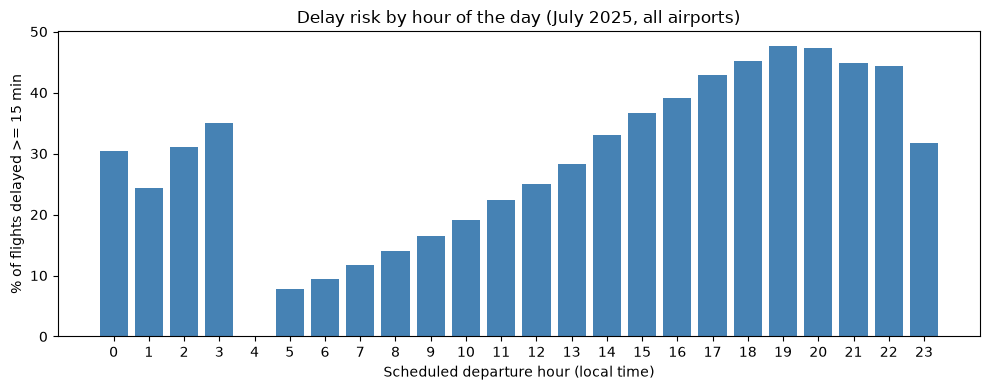

dep_hour,0,1,2,3,5,6,7,8,9,10,...,14,15,16,17,18,19,20,21,22,23
flights,1342.0,303.00,148.00,60.00,19235.00,43276.00,45347.00,41161.00,34807.00,37490.00,...,35174.00,34634.00,34114.00,37404.00,35286.00,33911.00,28795.00,21879.00,15811.00,6237.00
mean_delay,18.0,23.06,18.24,46.90,4.64,6.19,6.08,7.84,8.59,10.60,...,25.69,28.40,31.66,38.07,38.88,41.16,38.51,35.55,34.35,23.09
share_15,0.3,0.24,0.31,0.35,0.08,0.09,0.12,0.14,0.16,0.19,...,0.33,0.37,0.39,0.43,0.45,0.48,0.47,0.45,0.44,0.32


In [12]:
def scheduled_hour(hhmm: pd.Series) -> pd.Series:
    """Local scheduled hour (0-23) from an 'HHMM' text column; '2400' counts as hour 0."""
    return hhmm.str.zfill(4).str[:2].astype(int) % 24


flown = flown.assign(dep_hour=scheduled_hour(flown["CRSDepTime"]),
                     late15=flown["DepDelay"] >= 15)
by_hour = flown.groupby("dep_hour").agg(flights=("DepDelay", "size"),
                                        mean_delay=("DepDelay", "mean"),
                                        share_15=("late15", "mean"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_hour.index, 100 * by_hour["share_15"], color="steelblue")
ax.set_xlabel("Scheduled departure hour (local time)")
ax.set_ylabel("% of flights delayed >= 15 min")
ax.set_title("Delay risk by hour of the day (July 2025, all airports)")
ax.set_xticks(range(24))
plt.tight_layout()
plt.show()
by_hour.round(2).T

**What:** the same two numbers for each of our 10 hubs (departures only).
**Why:** if hubs behave very differently, the airport is a useful input, and the error analysis (Phase 4) must look per hub.

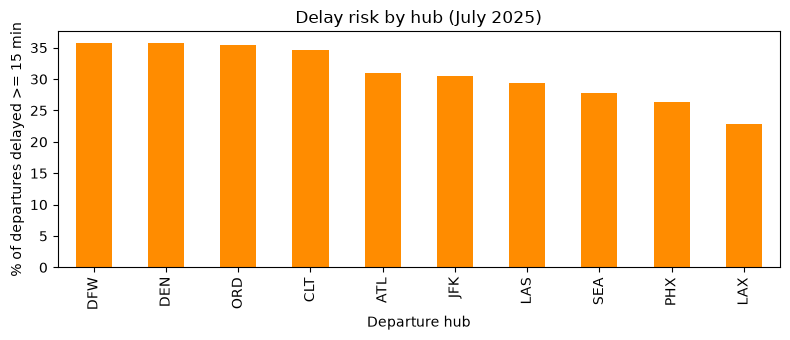

,flights,mean_delay,share_15
Origin,,,
DFW,28061,25.74,0.36
DEN,28996,27.90,0.36
ORD,29711,28.74,0.35
CLT,16067,26.15,0.35
ATL,28098,21.39,0.31
JFK,8685,26.44,0.31
LAS,15555,17.96,0.29
SEA,16349,15.42,0.28
PHX,15576,16.70,0.26


In [13]:
hub_flown = flown[flown["Origin"].isin(HUBS)]
by_hub = (hub_flown.groupby("Origin")
          .agg(flights=("DepDelay", "size"), mean_delay=("DepDelay", "mean"),
               share_15=("late15", "mean"))
          .sort_values("share_15", ascending=False))

ax = (100 * by_hub["share_15"]).plot.bar(figsize=(8, 3.5), color="darkorange")
ax.set_xlabel("Departure hub")
ax.set_ylabel("% of departures delayed >= 15 min")
ax.set_title("Delay risk by hub (July 2025)")
plt.tight_layout()
plt.show()
by_hub.round(2)

**What:** the same for each airline.
**Why:** airlines have different schedules, buffers and networks: the airline is likely a strong input.

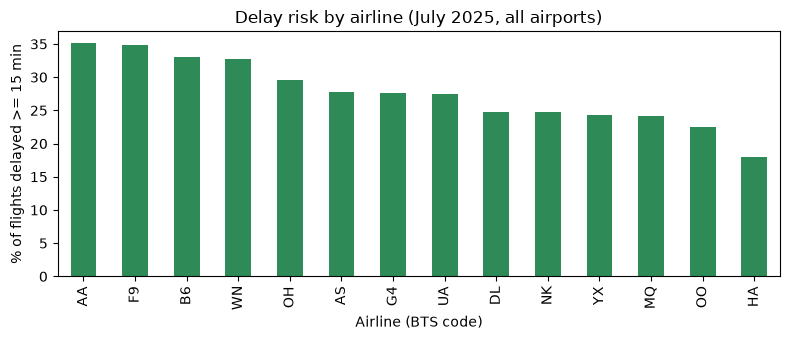

,flights,mean_delay,share_15
Reporting_Airline,,,
AA,84893,31.35,0.35
F9,15940,29.59,0.35
B6,19647,28.87,0.33
WN,124072,20.53,0.33
OH,19698,29.80,0.30
AS,23107,13.73,0.28
G4,13916,21.56,0.28
UA,68570,23.54,0.28
DL,92746,17.28,0.25


In [14]:
by_airline = (flown.groupby("Reporting_Airline")
              .agg(flights=("DepDelay", "size"), mean_delay=("DepDelay", "mean"),
                   share_15=("late15", "mean"))
              .sort_values("share_15", ascending=False))

ax = (100 * by_airline["share_15"]).plot.bar(figsize=(8, 3.5), color="seagreen")
ax.set_xlabel("Airline (BTS code)")
ax.set_ylabel("% of flights delayed >= 15 min")
ax.set_title("Delay risk by airline (July 2025, all airports)")
plt.tight_layout()
plt.show()
by_airline.round(2)

**Question:** Why do delays grow later in the day? Which hub and which airline stand out, and is one month enough to trust that ranking?

**My answer:** At 5 a.m. the mean delay is 4.6 min (8 % late); at 19 h it’s 41.2 min (48 % late).
Why: (1) The first morning flights use planes that parked overnight, so nothing is late yet. (2) Each late arrival makes the next departure late (propagation), and buffers get used up during the day. (3) In July, afternoon thunderstorms hit and air-traffic restrictions build up (NAS delays). (4) Peak traffic in the afternoon and evening.
Hubs: DFW and DEN have the highest share (36 %), and ORD has the highest mean (28.7 min). LAX is the best (23 %, 15.6 min). West Coast hubs are the least delayed in July (fewer summer storms).
Airlines: AA is worst (31.4 min, 35 %), HA (Hawaiian) is best (9.7 min, 18 %).
One month: right, and the stronger reason is that July is thunderstorm season, so the ranking may only describe summer. The gaps between the top hubs are small (0.35 vs 0.36), so they could swap in another month.

## 6. The delay-cause columns (analysis only)

> ⚠️ **These columns are NEVER model inputs.** `CarrierDelay`, `WeatherDelay`, `NASDelay`, `SecurityDelay`
> and `LateAircraftDelay` are filled **after** the flight, by the airline. Using them would be leakage
> (Golden rule 2). We look at them only to understand *why* flights are late.

**What:** when are the cause columns filled? BTS fills them for **arrival** delays ≥ 15 min, so we compare with `ArrDel15`, not `DepDel15`.
**Why:** if we compared with the departure flag we would see "errors" that are not errors.

In [15]:
CAUSES = ["CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]

cause_filled = df[CAUSES].notna().any(axis=1)
arr15 = df["ArrDel15"].map({0.0: "0 (on time)", 1.0: "1 (late >= 15)"}).fillna("missing")
pd.crosstab(arr15, cause_filled, rownames=["ArrDel15"], colnames=["cause columns filled"])

cause columns filled,False,True
ArrDel15,,
0 (on time),435799,0
1 (late >= 15),0,177012
missing,18617,0


**What:** out of all delay minutes explained by a cause, what share comes from each cause?
**Why:** this answers the CLAUDE.md question "what share of delay minutes is *late aircraft*?". A big share = propagation matters, which is the whole point of the rotation modality.

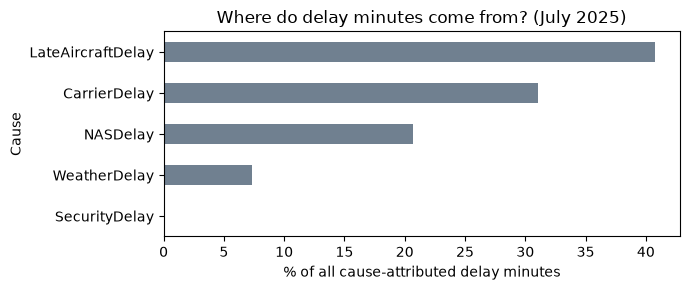

,minutes,% of total
CarrierDelay,4477900,31.1
WeatherDelay,1057529,7.3
NASDelay,2985238,20.7
SecurityDelay,15270,0.1
LateAircraftDelay,5880680,40.8


In [16]:
minutes = df[CAUSES].sum()
share = 100 * minutes / minutes.sum()

ax = share.sort_values().plot.barh(figsize=(7, 3), color="slategray")
ax.set_xlabel("% of all cause-attributed delay minutes")
ax.set_ylabel("Cause")
ax.set_title("Where do delay minutes come from? (July 2025)")
plt.tight_layout()
plt.show()
pd.DataFrame({"minutes": minutes.astype(int), "% of total": share.round(1)})

**Question:** What share of delay minutes is 'late aircraft'? What does it say about delay propagation, and why can none of these columns be a model input?

**My answer:** the most commun thing causing delay is the delay of a flight just before it , and none of the columns cannot be amodel input since they will be a leakge because they will help model find answer or something like this 

---
*End of batch 1. Batch 2 (UTC times, one tail through a day, ground-time distribution and chain-break threshold, consistency check, summary) comes next.*

## 7. From local clock times to UTC

**What:** find the time zone of every airport with `airportsdata`, and count the airports that have none.
**Why:** BTS times are **local clock times** at each airport. To put flights from different airports on one timeline
(and later to join weather and radar, which are in UTC), every time must first become UTC (Golden rule 1).

We use the time-zone **name** (e.g. `America/Phoenix`), never a fixed number of hours per zone: the name knows
the summer/winter rules of that place. Renamed airports go through `airport_aliases` from `config.yaml` first (`DJT` → `PBI`).

In [17]:
# zoneinfo is in the standard library: it finds the time-zone rules by NAME.
from zoneinfo import ZoneInfo

import airportsdata
import numpy as np

# dict: "ATL" -> {"tz": "America/New_York", "lat": ..., "lon": ..., ...}
AIRPORTS = airportsdata.load("IATA")
# {"DJT": "PBI"}: code seen in BTS -> code known to airportsdata
ALIASES = cfg.get("airport_aliases") or {}


def tz_name(iata: str) -> str | None:
    """Time-zone NAME of an airport (e.g. 'America/Phoenix'); None if unknown to airportsdata."""
    info = AIRPORTS.get(ALIASES.get(iata, iata))      # alias first, then look the airport up
    return info["tz"] if info else None


# Every airport used in July. "|" between two sets = union (in one, in the other, or in both).
codes = sorted(set(df["Origin"]) | set(df["Dest"]))
no_tz = [c for c in codes if not tz_name(c)]
print(f"airports in the data: {len(codes)} | without a time zone: {len(no_tz)} {no_tz}")
pd.Series([tz_name(c) for c in codes if tz_name(c)]).value_counts().to_frame("airports")

airports in the data: 345 | without a time zone: 0 []


,airports
America/Chicago,115
America/New_York,106
America/Denver,41
America/Los_Angeles,37
America/Anchorage,17
America/Phoenix,6
Pacific/Honolulu,5
America/Detroit,3
America/Boise,3
America/Puerto_Rico,3


**What:** the UTC offset of PHX, DEN and LAX in July and in January.
**Why:** Arizona (PHX) has **no daylight saving time**. Phoenix and Denver are both "Mountain time", but in summer
Denver moves its clocks and Phoenix does not. So in July Phoenix has the same clock as Los Angeles, and in January the same
clock as Denver. A table "Mountain time = UTC−7" would be wrong for one of them half of the year: this is why we use zone names.

In [18]:
def utc_offset_hours(iata: str, day: str) -> float:
    """Local time minus UTC, in hours, at noon of that day (negative = behind UTC)."""
    noon = pd.Timestamp(f"{day} 12:00", tz=ZoneInfo(tz_name(iata)))
    return noon.utcoffset().total_seconds() / 3600


three = ["PHX", "DEN", "LAX"]
pd.DataFrame({
    "time zone": {a: tz_name(a) for a in three},
    "UTC offset on 2025-07-15": {a: utc_offset_hours(a, "2025-07-15") for a in three},
    "UTC offset on 2025-01-15": {a: utc_offset_hours(a, "2025-01-15") for a in three},
})

,time zone,UTC offset on 2025-07-15,UTC offset on 2025-01-15
PHX,America/Phoenix,-7.0,-7.0
DEN,America/Denver,-6.0,-7.0
LAX,America/Los_Angeles,-7.0,-8.0


### 7.1 Is the clock time valid?

**What:** `valid_hhmm(s)` says if a value is a real clock time **written as text**: 1 to 4 digits (`0`–`9`) that give a time
between `00:00` and `23:59` once leading zeros are added (`"659"` → `"0659"` = 06:59), or exactly `"2400"` (midnight at the end of the day).
Everything else is refused: `""`, spaces, missing values (`NaN`), malformed text (`"12:3"`, `"12345"`), and also **numbers** (`930`):
BTS times are read as text on purpose (section 0), and a number has already lost its leading zeros, so we do not guess.
Then we count the invalid `CRSDepTime` / `CRSArrTime` values of July.

**Why:** our conversion works by "midnight + hours + minutes". Without a check, `"1260"` (minute 60) silently becomes 13:00
and `"2500"` becomes 01:00 of the **next day**: a wrong time and no error. A wrong value must be **rejected**, never "repaired" by the arithmetic.
The check looks at the **original** value **before** adding zeros: otherwise `""` would become `"0000"` and look like a valid midnight.

In [19]:
import re


def valid_hhmm(s) -> bool:
    """True if `s` is a clock-time TEXT: 1 to 4 digits giving 00:00-23:59 once padded with
    leading zeros ('659' -> '0659' = 06:59), or exactly '2400'.

    False for anything else: '', spaces, NaN, malformed text, and numbers (930 or 930.0):
    numbers are NOT supported, because BTS times are read as text and a number has
    already lost its leading zeros.
    """
    if not isinstance(s, str):                 # NaN, None, int, float... are not text: refused
        return False
    if s == "2400":                            # midnight at the END of the day: allowed
        return True
    # Check the ORIGINAL text first: 1 to 4 characters, each a digit 0-9 (fullmatch = whole text).
    # Padding first would be a trap: "".zfill(4) == "0000" would look like a valid midnight.
    if not re.fullmatch(r"[0-9]{1,4}", s):
        return False
    s = s.zfill(4)                             # "659" -> "0659"
    return int(s[:2]) <= 23 and int(s[2:]) <= 59


for good in ["659", "0659", "0000", "2359", "2400"]:
    assert valid_hhmm(good), f"{good!r} should be accepted"
for bad in ["", "  ", " 659", "1260", "2500", "2401", "12345", "12:3",
            930, 930.0, float("nan"), None]:
    assert not valid_hhmm(bad), f"{bad!r} should be rejected"
print("valid_hhmm: all checks passed")

for col in ["CRSDepTime", "CRSArrTime"]:
    ok = df[col].map(valid_hhmm)               # one True/False per row
    print(f"July {col}: invalid {(~ok).sum():,} | equal to '2400': {df[col].eq('2400').sum():,}")

valid_hhmm: all checks passed
July CRSDepTime: invalid 0 | equal to '2400': 1
July CRSArrTime: invalid 0 | equal to '2400': 0


### 7.2 Daylight-saving time: the two special hours of a year

In the US the clocks change at **02:00 local time**:
- **March (spring forward):** 02:00 jumps to 03:00. A local time like **02:30 does not exist** that night (*nonexistent*).
- **November (fall back):** 02:00 goes back to 01:00. A local time like **01:30 happens twice**, first in summer time (UTC−4 in Atlanta),
  then one hour later in winter time (UTC−5) (*ambiguous*).

BTS gives only `FlightDate` + `HHMM`, so for these times we cannot know which moment the airline meant.
(Arizona and Hawaii do not change their clocks, so they never have this problem.)

**Our policy:**
1. A nonexistent or ambiguous local time is **not guessed**: its UTC time stays missing (`NaT`).
2. A flag column says why: `dep_time_issue` = `"invalid"` / `"dst_ambiguous"` / `"dst_nonexistent"` / `""` (no problem).
   (A fifth value, `"no_time_zone"`, would mark an airport unknown to `airportsdata`; July has none, see the start of this section.)
3. These flights **stay in the data** with their flag, and their number is **reported** (Golden rule 5: no silent drop).
   They are **flagged now, in this notebook**; whether and how they are excluded from chains and labels is a **Silver decision**
   (nothing is excluded in sections 8–11). The original BTS columns are never modified.

**What:** `local_time_issue(local, zone)` tells if a local clock time is `""`, `"dst_ambiguous"` or `"dst_nonexistent"` in a zone,
checked on hand-made examples. `both_utc_times` shows the two possible UTC times of an ambiguous one.
**Why:** a small function we can test by hand; `to_utc` (next) uses it to stop with a clear error.

How it works: Python's `datetime` has a `fold` attribute that means "first (`fold=0`) or second (`fold=1`) time the clock shows this time".
Normally both give the same UTC offset. If the offsets differ, the time sits at a clock change: then we go to UTC and come back;
if we get the same clock time back, it exists (twice → ambiguous); if not, it never existed (nonexistent).

In [20]:
from datetime import UTC


def local_time_issue(local, zone: str) -> str:
    """'' if the local clock time `local` happens exactly once in time zone `zone`,
    'dst_ambiguous' if it happens twice (November),
    'dst_nonexistent' if it never happens (March)."""
    naive = pd.Timestamp(local).to_pydatetime()            # plain Python datetime, no zone yet
    first = naive.replace(tzinfo=ZoneInfo(zone), fold=0)   # "the first time the clock shows it"
    second = naive.replace(tzinfo=ZoneInfo(zone), fold=1)  # "the second time"
    if first.utcoffset() == second.utcoffset():
        return ""                                          # normal time: one moment only
    # Next to a clock change: go to UTC and back. Same clock time again -> it exists (twice).
    back = first.astimezone(UTC).astimezone(ZoneInfo(zone)).replace(tzinfo=None)
    return "dst_ambiguous" if back == naive else "dst_nonexistent"


def both_utc_times(local, zone: str) -> tuple[pd.Timestamp, pd.Timestamp]:
    """The two UTC moments of an ambiguous local time: (summer-time, winter-time reading)."""
    naive = pd.Timestamp(local).to_pydatetime()
    return tuple(pd.Timestamp(naive.replace(tzinfo=ZoneInfo(zone), fold=f)).tz_convert("UTC")
                 for f in (0, 1))


ATL_TZ, PHX_TZ = tz_name("ATL"), tz_name("PHX")
assert local_time_issue("2025-11-02 01:30", ATL_TZ) == "dst_ambiguous"     # 01:30 happens twice
assert local_time_issue("2025-03-09 02:30", ATL_TZ) == "dst_nonexistent"   # 02:30 is skipped
assert local_time_issue("2025-11-02 02:30", ATL_TZ) == ""                  # after the change
assert local_time_issue("2025-07-15 14:30", ATL_TZ) == ""                  # an ordinary day
assert local_time_issue("2025-03-09 02:30", PHX_TZ) == ""                  # Arizona: no change
assert local_time_issue("2025-11-02 01:30", PHX_TZ) == ""
summer, winter = both_utc_times("2025-11-02 01:30", ATL_TZ)
assert summer == pd.Timestamp("2025-11-02 05:30", tz="UTC")                # 01:30 at UTC-4
assert winter == pd.Timestamp("2025-11-02 06:30", tz="UTC")                # 01:30 at UTC-5
print("local_time_issue / both_utc_times: all checks passed")
print(f"ATL 2025-11-02 01:30 could be {summer} (summer time) or {winter} (winter time):",
      "we do not guess")

local_time_issue / both_utc_times: all checks passed
ATL 2025-11-02 01:30 could be 2025-11-02 05:30:00+00:00 (summer time) or 2025-11-02 06:30:00+00:00 (winter time): we do not guess


### 7.3 One flight: `to_utc`

**What:** `to_utc(flight_date, hhmm_str, iata)`: one local clock time → one UTC timestamp, checked with `assert` on values we can compute by hand.
It now **refuses** what it cannot convert safely: an invalid clock time, an airport without a time zone, or a daylight-saving hour
(nonexistent or ambiguous). Each case stops with a clear `ValueError` that says what is wrong.
**Why:** a small function for **one** flight is easy to read and to test. `"2400"` means midnight at the **end** of the day, so it is `00:00` of the **next** day.
An error is better than a silent wrong time: a wrong UTC time would attach the wrong weather to a flight without anyone noticing.

An `assert` does nothing when its condition is true and stops with an error when it is false: a tiny test.
(The real tests go in `tests/test_time.py`, step 1.5.)

In [21]:
def local_clock(flight_date, hhmm_str: str) -> pd.Timestamp:
    """Date + 'HHMM' text -> local clock time (no time zone attached).

    ValueError if the value is not a valid clock-time text (rule of valid_hhmm; no numbers).
    """
    if not valid_hhmm(hhmm_str):                     # checks the ORIGINAL value, before padding
        raise ValueError(f"invalid clock time {hhmm_str!r}: expected text of 1-4 digits "
                         "giving 00:00-23:59, or exactly '2400' (numbers are not accepted)")
    hhmm = hhmm_str.zfill(4)                         # "659" -> "0659"
    hours, minutes = int(hhmm[:2]), int(hhmm[2:])
    # Start at midnight of the flight date and ADD the hours and minutes.
    # Adding 24 hours lands on 00:00 of the next day, so "2400" needs no special case.
    return pd.Timestamp(flight_date).normalize() + pd.Timedelta(hours=hours, minutes=minutes)


def to_utc(flight_date, hhmm_str: str, iata: str) -> pd.Timestamp:
    """Local clock time 'HHMM' at airport `iata` on `flight_date` -> UTC timestamp.

    '2400' is midnight at the END of the day, so it becomes 00:00 of the next day.
    Raises ValueError for an invalid time, an unknown time zone, or a daylight-saving hour
    (nonexistent in March, ambiguous in November): these are never guessed.
    """
    local = local_clock(flight_date, hhmm_str)
    zone = tz_name(iata)
    if zone is None:
        raise ValueError(f"no time zone known for airport {iata!r}")
    issue = local_time_issue(local, zone)
    if issue:
        raise ValueError(f"{local:%Y-%m-%d %H:%M} at {iata} ({zone}) is {issue}: "
                         "not converted, never guessed")
    # 1) say "this clock time is in the airport's zone" (the zone picks summer or winter offset),
    # 2) convert to UTC.
    return local.tz_localize(ZoneInfo(zone)).tz_convert("UTC")


# summer: Atlanta is UTC-4
assert to_utc("2025-07-15", "1430", "ATL") == pd.Timestamp("2025-07-15 18:30", tz="UTC")
# Arizona: UTC-7 all year
assert to_utc("2025-07-15", "1430", "PHX") == pd.Timestamp("2025-07-15 21:30", tz="UTC")
# winter: Atlanta is UTC-5
assert to_utc("2025-01-15", "1430", "ATL") == pd.Timestamp("2025-01-15 19:30", tz="UTC")
# "2400" = 00:00 of the next day
assert to_utc("2025-07-15", "2400", "ATL") == to_utc("2025-07-16", "0000", "ATL")
print("all 4 conversion checks passed")
print("ATL 14:30 on 2025-07-15 ->", to_utc("2025-07-15", "1430", "ATL"))
print("PHX 14:30 on 2025-07-15 ->", to_utc("2025-07-15", "1430", "PHX"))
print("ATL 24:00 on 2025-07-15 ->", to_utc("2025-07-15", "2400", "ATL"))

# These must be REFUSED with a ValueError (try/except catches the error so the notebook goes on).
must_fail = [("2025-07-15", "1260", "ATL"), ("2025-07-15", "2500", "ATL"),   # invalid clock times
             ("2025-07-15", "", "ATL"), ("2025-07-15", 930, "ATL"),          # empty text, a number
             ("2025-11-02", "0130", "ATL"),                                  # ambiguous (November)
             ("2025-03-09", "0230", "ATL")]                                  # nonexistent (March)
for date, hhmm, iata in must_fail:
    try:
        to_utc(date, hhmm, iata)
    except ValueError as err:
        print("refused as expected:", err)
    else:                                          # runs only if NO error was raised
        raise AssertionError(f"{hhmm} at {iata} on {date} should have been refused")

all 4 conversion checks passed
ATL 14:30 on 2025-07-15 -> 2025-07-15 18:30:00+00:00
PHX 14:30 on 2025-07-15 -> 2025-07-15 21:30:00+00:00
ATL 24:00 on 2025-07-15 -> 2025-07-16 04:00:00+00:00
refused as expected: invalid clock time '1260': expected text of 1-4 digits giving 00:00-23:59, or exactly '2400' (numbers are not accepted)
refused as expected: invalid clock time '2500': expected text of 1-4 digits giving 00:00-23:59, or exactly '2400' (numbers are not accepted)
refused as expected: invalid clock time '': expected text of 1-4 digits giving 00:00-23:59, or exactly '2400' (numbers are not accepted)
refused as expected: invalid clock time 930: expected text of 1-4 digits giving 00:00-23:59, or exactly '2400' (numbers are not accepted)
refused as expected: 2025-11-02 01:30 at ATL (America/New_York) is dst_ambiguous: not converted, never guessed
refused as expected: 2025-03-09 02:30 at ATL (America/New_York) is dst_nonexistent: not converted, never guessed


### 7.4 The whole table: `to_utc_series` and the flag column

**What:** the same conversion for the **whole table** → new column `sched_dep_utc`. The arrival `sched_arr_utc` comes in 7.4b, after a check of the duration.
A second new column, `dep_time_issue`, says **why** a `sched_dep_utc` is missing (`"invalid"`, `"dst_ambiguous"`, `"dst_nonexistent"`,
`"no_time_zone"`) or is `""` when there is no problem. `CRSDepTime` itself is not touched.

**Why a second function:** calling `to_utc` 631,428 times takes about 20 seconds. `to_utc_series` does the same steps on whole columns,
one time zone at a time (under a second). Where `to_utc` would stop with an error, `to_utc_series` writes `NaT` (missing) instead,
so one bad row does not stop the whole table. The flag column keeps the reason, so nothing goes missing silently.

**Why not convert `CRSArrTime` directly?** Two traps:
1. **Overnight arrival:** BTS gives one date (`FlightDate` = the departure date) and an arrival *clock time*. A flight leaving at 23:00
   and landing at 01:10 arrives the **next day**, but nothing in `CRSArrTime` says so.
2. **Destination time zone:** `CRSArrTime` is on the *destination's* clock, which may be another zone than the departure.

`CRSElapsedTime` is a **duration** (scheduled minutes from gate to gate). A duration has no clock and no time zone:
departure UTC + duration = arrival UTC, always.

The hand-made examples of 7.1–7.3 are checked again on the column version at the end of the cell.

In [22]:
def local_clock_series(dates: pd.Series, hhmm: pd.Series) -> pd.Series:
    """local_clock for whole columns: date + 'HHMM' -> local clock time (no zone).

    Invalid times -> NaT."""
    ok = hhmm.map(valid_hhmm)                      # same rule as local_clock (original values)
    # Invalid rows get a harmless "0000" so the arithmetic below cannot fail;
    # .where(ok) at the end puts them back to NaT (missing).
    hhmm = hhmm.where(ok, "0000").str.zfill(4)
    # Midnight of the date + hours + minutes ("2400" -> next day 00:00).
    local = (dates
             + pd.to_timedelta(hhmm.str[:2].astype(int), unit="h")
             + pd.to_timedelta(hhmm.str[2:].astype(int), unit="m"))
    return local.where(ok)


def to_utc_series(dates: pd.Series, hhmm: pd.Series, iata: pd.Series) -> pd.Series:
    """Same as to_utc, for whole columns (same row index in and out).

    Where to_utc raises an error (invalid time, unknown zone, daylight-saving hour), this gives NaT.
    time_issue_series says why.
    """
    local = local_clock_series(dates, hhmm)
    zone = iata.map(tz_name)                       # one zone name per row (missing if unknown)
    pieces = []
    for name, part in local.groupby(zone):         # all the rows of one zone together
        # "NaT" = missing value, not a guess, for the 2 special daylight-saving hours of a year
        in_zone = part.dt.tz_localize(ZoneInfo(name), ambiguous="NaT", nonexistent="NaT")
        pieces.append(in_zone.dt.tz_convert("UTC"))
    # Rows of an unknown zone are in no group: reindex gives them NaT.
    return pd.concat(pieces).reindex(dates.index)  # back to the original row order


def time_issue_series(dates: pd.Series, hhmm: pd.Series, iata: pd.Series,
                      utc: pd.Series) -> pd.Series:
    """Why each UTC time in `utc` is missing: 'invalid', 'no_time_zone', 'dst_ambiguous',
    'dst_nonexistent', or '' when there is no problem."""
    issue = pd.Series("", index=dates.index)
    ok = hhmm.map(valid_hhmm)
    zone = iata.map(tz_name)
    issue.loc[~ok] = "invalid"
    issue.loc[ok & zone.isna()] = "no_time_zone"
    # Whatever is still missing can only be a daylight-saving hour: a handful of rows a year,
    # so we check them one by one with local_time_issue.
    for i in issue.index[utc.isna() & issue.eq("")]:
        issue.loc[i] = local_time_issue(local_clock(dates.loc[i], hhmm.loc[i]), zone.loc[i])
    return issue


df["sched_dep_utc"] = to_utc_series(df["FlightDate"], df["CRSDepTime"], df["Origin"])
df["dep_time_issue"] = time_issue_series(df["FlightDate"], df["CRSDepTime"], df["Origin"],
                                         df["sched_dep_utc"])
# No silent drop: every missing departure must have a reason in the flag column.
assert df.loc[df["sched_dep_utc"].isna(), "dep_time_issue"].ne("").all()
print("missing sched_dep_utc:", df["sched_dep_utc"].isna().sum())
print("dep_time_issue in July:",
      df["dep_time_issue"].replace("", "(no problem)").value_counts().to_dict())

# The hand-made examples again, on the column functions.
ex = pd.DataFrame({
    "FlightDate": pd.to_datetime(["2025-11-02", "2025-03-09", "2025-03-09", "2025-07-15",
                                  "2025-07-15", "2025-07-15", "2025-07-15"]),
    "CRSDepTime": ["0130", "0230", "0230", "1260", "2500", "2400", "1430"],
    "Origin": ["ATL", "ATL", "PHX", "ATL", "ATL", "ATL", "ATL"],
    "expected": ["dst_ambiguous", "dst_nonexistent", "", "invalid", "invalid", "", ""],
})
ex["utc"] = to_utc_series(ex["FlightDate"], ex["CRSDepTime"], ex["Origin"])
ex["issue"] = time_issue_series(ex["FlightDate"], ex["CRSDepTime"], ex["Origin"], ex["utc"])
assert ex["issue"].eq(ex["expected"]).all()
assert ex["utc"].isna().eq(ex["expected"].ne("")).all()     # NaT exactly where there is an issue
print("hand-made examples on the column functions: all checks passed")
ex

missing sched_dep_utc: 0
dep_time_issue in July: {'(no problem)': 631428}
hand-made examples on the column functions: all checks passed


,FlightDate,CRSDepTime,Origin,expected,utc,issue
0,2025-11-02,0130,ATL,dst_ambiguous,NaT,dst_ambiguous
1,2025-03-09,0230,ATL,dst_nonexistent,NaT,dst_nonexistent
2,2025-03-09,0230,PHX,,2025-03-09 09:30:00+00:00,
3,2025-07-15,1260,ATL,invalid,NaT,invalid
4,2025-07-15,2500,ATL,invalid,NaT,invalid
5,2025-07-15,2400,ATL,,2025-07-16 04:00:00+00:00,
6,2025-07-15,1430,ATL,,2025-07-15 18:30:00+00:00,


### 7.4b Is the duration usable?

**What:** before computing `sched_arr_utc = sched_dep_utc + CRSElapsedTime`, check the duration. A `CRSElapsedTime` that is **missing**,
**not a finite number** (infinite) or **zero or negative** cannot be a scheduled flight time: the row gets
`duration_issue = "invalid_duration"` and its arrival stays `NaT`. `CRSElapsedTime` itself is kept as it is.
**Why:** an arrival is only as good as the duration it is built from; a missing or negative duration would give no arrival or one
before the departure. This is a light check for exploration: it only catches values that are **impossible**.
A duration that is possible but wrong (e.g. exactly 24 h too long) passes it, see 7.9. No "too long" threshold is invented here.

In [23]:
def usable_duration(minutes: pd.Series) -> pd.Series:
    """True where a scheduled duration (minutes) can be used: a finite number above 0."""
    # np.isfinite is False for NaN (missing) and for +-infinity, so one test covers both.
    return pd.Series(np.isfinite(minutes), index=minutes.index) & (minutes > 0)


assert usable_duration(pd.Series([120.0, np.nan, np.inf, 0.0, -5.0])).tolist() == [
    True, False, False, False, False]

dur = df["CRSElapsedTime"]                         # float column, never modified
usable = usable_duration(dur)
df["duration_issue"] = np.where(usable, "", "invalid_duration")   # flag text per row
# A duration has no time zone: departure (UTC) + scheduled minutes = arrival (UTC).
# dur.where(usable) -> NaN where the duration is not usable, so the arrival becomes NaT (no guess).
df["sched_arr_utc"] = df["sched_dep_utc"] + pd.to_timedelta(dur.where(usable), unit="m")

print(f"July CRSElapsedTime: missing {dur.isna().sum():,} | infinite {np.isinf(dur).sum():,} "
      f"| zero or negative {(dur <= 0).sum():,} | flagged invalid_duration {(~usable).sum():,}")
print(f"missing sched_arr_utc: {df['sched_arr_utc'].isna().sum():,}")
# No silent drop: every missing arrival has a reason (departure issue or duration issue).
no_reason = df["sched_arr_utc"].isna() & df["dep_time_issue"].eq("") & df["duration_issue"].eq("")
assert not no_reason.any()

July CRSElapsedTime: missing 0 | infinite 0 | zero or negative 0 | flagged invalid_duration 0
missing sched_arr_utc: 0


### 7.5 Real ambiguous flights (November 2024 and November 2025)

**What:** read **only 4 columns** (`FlightDate`, `Reporting_Airline`, `Origin`, `CRSDepTime`) of the two November files, count the flags,
and list the flights whose scheduled departure falls in the repeated hour, with **both** possible UTC times.
**Why:** July has no clock change, so the policy of 7.2 is only tested on hand-made examples so far. November shows how many real
flights it touches (a few per year) and that it does not need a guess to be safe: they are kept, flagged and counted;
how they are handled in chains and labels is decided in Silver. Reading 4 columns instead of all is fast and light in memory.

(March, the "nonexistent" month, was checked the same way for 2024, 2025 and 2026: 0 scheduled departures fall in the skipped hour.
The code still handles that case, as the hand-made example of 7.2 shows.)

In [24]:
NOV_COLS = ["FlightDate", "Reporting_Airline", "Origin", "CRSDepTime"]
found = []
for month in ["2024_11", "2025_11"]:
    # same folder as the July file
    nov = read_bts_month(BTS_ZIP.parent / f"bts_{month}.zip", NOV_COLS)
    nov["FlightDate"] = pd.to_datetime(nov["FlightDate"], format="%Y-%m-%d")
    utc = to_utc_series(nov["FlightDate"], nov["CRSDepTime"], nov["Origin"])
    nov["dep_time_issue"] = time_issue_series(nov["FlightDate"], nov["CRSDepTime"],
                                              nov["Origin"], utc)
    counts = nov["dep_time_issue"].value_counts()
    print(f"{month}: {len(nov):,} flights | invalid {counts.get('invalid', 0)} | "
          f"dst_ambiguous {counts.get('dst_ambiguous', 0)} | "
          f"dst_nonexistent {counts.get('dst_nonexistent', 0)} | "
          f"no_time_zone {counts.get('no_time_zone', 0)}")
    found.append(nov[nov["dep_time_issue"].ne("")])

flagged = pd.concat(found, ignore_index=True)
# Both possible UTC moments of each flagged departure (summer-time reading, winter-time reading).
options = [both_utc_times(local_clock(d, t), tz_name(a))
           for d, t, a in zip(flagged["FlightDate"], flagged["CRSDepTime"], flagged["Origin"],
                              strict=True)]
flagged["utc_if_summer_time"] = [first for first, _ in options]
flagged["utc_if_winter_time"] = [second for _, second in options]
flagged.assign(zone=flagged["Origin"].map(tz_name))

2024_11: 575,404 flights | invalid 0 | dst_ambiguous 6 | dst_nonexistent 0 | no_time_zone 0
2025_11: 570,550 flights | invalid 0 | dst_ambiguous 4 | dst_nonexistent 0 | no_time_zone 0


,FlightDate,Reporting_Airline,Origin,CRSDepTime,dep_time_issue,utc_if_summer_time,utc_if_winter_time,zone
0,2024-11-03,NK,LAS,0132,dst_ambiguous,2024-11-03 08:32:00+00:00,2024-11-03 09:32:00+00:00,America/Los_Angeles
1,2024-11-03,NK,LAS,0130,dst_ambiguous,2024-11-03 08:30:00+00:00,2024-11-03 09:30:00+00:00,America/Los_Angeles
2,2024-11-03,HA,LAS,0140,dst_ambiguous,2024-11-03 08:40:00+00:00,2024-11-03 09:40:00+00:00,America/Los_Angeles
3,2024-11-03,DL,ANC,0130,dst_ambiguous,2024-11-03 09:30:00+00:00,2024-11-03 10:30:00+00:00,America/Anchorage
4,2024-11-03,DL,FAI,0159,dst_ambiguous,2024-11-03 09:59:00+00:00,2024-11-03 10:59:00+00:00,America/Anchorage
5,2024-11-03,AA,LAX,0145,dst_ambiguous,2024-11-03 08:45:00+00:00,2024-11-03 09:45:00+00:00,America/Los_Angeles
6,2025-11-02,DL,FAI,0150,dst_ambiguous,2025-11-02 09:50:00+00:00,2025-11-02 10:50:00+00:00,America/Anchorage
7,2025-11-02,NK,LAS,0120,dst_ambiguous,2025-11-02 08:20:00+00:00,2025-11-02 09:20:00+00:00,America/Los_Angeles
8,2025-11-02,NK,LAX,0120,dst_ambiguous,2025-11-02 08:20:00+00:00,2025-11-02 09:20:00+00:00,America/Los_Angeles
9,2025-11-02,AA,LAX,0119,dst_ambiguous,2025-11-02 08:19:00+00:00,2025-11-02 09:19:00+00:00,America/Los_Angeles


### 7.6 Two functions, one answer

**What:** `to_utc` and `to_utc_series` agree on 2,000 random flights.
**Why:** getting the same number in two independent ways is the best check of a time conversion.
(The checks on **arrivals** follow in 7.7 and 7.8: they replace the old "`CRSArrTime < CRSDepTime`" count and the clock-only cross-check.)

In [25]:
# one-by-one function vs. column function (random_state=0 -> the same sample at every run)
sample = df.sample(2000, random_state=0)
# zip walks through the 3 columns together; strict=True = error if their lengths differ
rows = zip(sample["FlightDate"], sample["CRSDepTime"], sample["Origin"], strict=True)
one_by_one = pd.Series([to_utc(d, t, a) for d, t, a in rows], index=sample.index)
print("to_utc == to_utc_series on the sample:", (one_by_one == sample["sched_dep_utc"]).all())

to_utc == to_utc_series on the sample: True


### 7.7 Which flights really arrive the next day?

**What:** show `sched_arr_utc` on the **destination's** clock → the local arrival date. A flight is **overnight** when that date is after `FlightDate`.
Then a 2×2 table: the old clock test ("`CRSArrTime < CRSDepTime`") against this real, date-based answer.
**Why:** the clock test compares two clocks of **different time zones** and fails in both directions:
- **Flagged but not overnight:** a short flight going **west** gains clock time. ATL → BHM (Birmingham, Alabama) on 2025-07-06 leaves at 09:43
  Atlanta time (Eastern, UTC−4) = 13:43 UTC; after 54 min it lands at 14:37 UTC = **09:37 Birmingham time** (Central, UTC−5).
  The arrival clock (0937) is "before" the departure clock (0943), but it is the same morning.
- **Overnight but not flagged:** a flight that crosses the **International Date Line** going west. Honolulu → Guam leaves at 14:25 and lands at 18:05 local:
  18:05 > 14:25, yet it is 18:05 of the **next day** in Guam (UTC+10). The way back (Guam → Honolulu) even lands on the **previous** date.

The arrival we use (`sched_arr_utc` = departure + duration) was always right; only the overnight **test** was wrong.

In [26]:
def utc_to_local_series(utc: pd.Series, iata: pd.Series) -> pd.Series:
    """UTC timestamps -> local clock time at each row's airport (zone removed after converting)."""
    zone = iata.map(tz_name)
    # tz_localize(None) keeps the clock reading and drops the zone,
    # so rows of different zones fit in one column.
    pieces = [part.dt.tz_convert(ZoneInfo(name)).dt.tz_localize(None)
              for name, part in utc.groupby(zone)]
    return pd.concat(pieces).reindex(utc.index)


# arrival on the destination's clock
arr_local = utc_to_local_series(df["sched_arr_utc"], df["Dest"])
# Arrival local date minus departure date, in whole days:
# 0 = same date, 1 = next date, -1 = previous date.
day_diff = (arr_local.dt.normalize() - df["FlightDate"]).dt.days
print("arrival local date - FlightDate (days):", day_diff.value_counts().sort_index().to_dict())

clock_flag = df["CRSArrTime"] < df["CRSDepTime"]     # the OLD test (text comparison of 'HHMM')
overnight = day_diff >= 1                            # the real one: arrives on a later local date
table_2x2 = pd.crosstab(clock_flag.rename("CRSArrTime < CRSDepTime (clock test)"),
                        overnight.rename("arrives on a later local date"), margins=True)
print(table_2x2, "\n")

# One example of each wrong case, and of the "previous date" case.
SHOW = ["FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline", "Origin", "Dest",
        "CRSDepTime", "CRSArrTime", "CRSElapsedTime"]
atl_bhm = (df["Origin"].eq("ATL") & df["Dest"].eq("BHM") & df["FlightDate"].eq("2025-07-06")
           & df["CRSDepTime"].eq("0943"))
examples = pd.concat([df[atl_bhm],                                    # flagged, same date
                      df[~clock_flag & overnight].head(1),            # not flagged, next date
                      df[day_diff.eq(-1)].head(1)])                   # previous date
print(examples[SHOW].assign(
    arrival_local=arr_local[examples.index].dt.strftime("%Y-%m-%d %H:%M"),
    day_diff=day_diff[examples.index]).to_string(), "\n")

# Who is in the two wrong cells? Time zones of origin -> destination.
zones = df["Origin"].map(tz_name) + " -> " + df["Dest"].map(tz_name)
print("flagged but same date, top zone pairs:\n",
      zones[clock_flag & ~overnight].value_counts().head(5).to_string())
print("\nlater date but not flagged, routes:\n",
      (df["Origin"] + "->" + df["Dest"])[~clock_flag & overnight].value_counts().to_string())

arrival local date - FlightDate (days): {-1: 31, 0: 605997, 1: 25400}
arrives on a later local date          False   True     All
CRSArrTime < CRSDepTime (clock test)                       
False                                 605470     31  605501
True                                     558  25369   25927
All                                   606028  25400  631428 

       FlightDate Reporting_Airline  Flight_Number_Reporting_Airline Origin Dest CRSDepTime CRSArrTime  CRSElapsedTime     arrival_local  day_diff
149059 2025-07-06                DL                             2250    ATL  BHM       0943       0937            54.0  2025-07-06 09:37         0
253136 2025-07-29                UA                              201    HNL  GUM       1425       1805           460.0  2025-07-30 18:05         1
253137 2025-07-29                UA                              200    GUM  HNL       0715       1825           430.0  2025-07-28 18:25        -1 

flagged but same date, top zone pairs:

### 7.8 Arrival cross-check, with the date

**What:** compare our arrival (`sched_arr_utc` on the destination's clock, built from `CRSElapsedTime`) with the BTS arrival clock `CRSArrTime`,
**and** check the date: we place `CRSArrTime` on the closest day to our arrival, and that day must be `FlightDate` − 1, `FlightDate` or `FlightDate` + 1
(−1 only happens across the date line, see 7.7). Rows that fail get the flag `sched_inconsistent = True`; the table lists them with every
schedule field, and the count per airline is printed.
**Why:** the old check compared `HHMM` only, without any date.

⚠️ **This is a plausibility check, not a proof of the arrival date.** A duration wrong by exactly 24 h lands on the same clock time one day
later and still passes (example in 7.9).

**What we do with the disagreeing rows:** we **cannot tell which field is wrong** (`CRSDepTime`, `CRSArrTime` or `CRSElapsedTime`).
So the original values are **kept** (no "fix") and the row is **flagged** here (`sched_inconsistent`); the count goes into the data-quality report.
Whether and how these flights are excluded or handled in chains and labels is a **Silver decision**: nothing is excluded in sections 8–11.
A schedule inconsistency also does **not** prove that the `DepDelay` label is wrong: `DepDelay` is built from the departure times only,
and the error may be in the arrival fields.

In [27]:
def arrival_check(dates: pd.Series, crs_arr: pd.Series, arr_local: pd.Series) -> pd.DataFrame:
    """Compare our arrival `arr_local` (destination clock) with CRSArrTime put on the closest day.

    day_shift: whole days between them (0 = same date, 1 = next date, -1 = previous date).
    diff_min: minutes left once the date is lined up (0 = the clocks agree;
    NaN if CRSArrTime is invalid).
    """
    bts_clock = local_clock_series(dates, crs_arr)      # CRSArrTime placed on the flight date
    gap_min = (arr_local - bts_clock).dt.total_seconds() / 60
    day_shift = (gap_min / 1440).round()                # closest whole number of days
    return pd.DataFrame({"day_shift": day_shift, "diff_min": gap_min - 1440 * day_shift})


check = arrival_check(df["FlightDate"], df["CRSArrTime"], arr_local)
# no arrival (departure or duration issue) -> nothing to compare
can_check = df["sched_arr_utc"].notna()
# also False when CRSArrTime is invalid (the difference is then NaN)
clock_ok = check["diff_min"].eq(0)
# expected arrival date: FlightDate -1, 0 or +1 day
date_ok = check["day_shift"].between(-1, 1)
df["sched_inconsistent"] = can_check & ~(clock_ok & date_ok)

print(f"checked: {can_check.sum():,} | not checkable (no sched_arr_utc): {(~can_check).sum():,}")
print(f"  clock disagrees: {(can_check & ~clock_ok).sum():,} | date outside FlightDate +-1 day: "
      f"{(can_check & clock_ok & ~date_ok).sum():,}")
agree = can_check & ~df["sched_inconsistent"]
print(f"  sched_inconsistent: {df['sched_inconsistent'].sum():,} "
      f"({100 * df['sched_inconsistent'].mean():.3f} % of flights) | "
      f"agree: {100 * agree.mean():.3f} %")

bad = df["sched_inconsistent"]
print("  sched_inconsistent per airline:",
      df.loc[bad, "Reporting_Airline"].value_counts().to_dict())
df.loc[bad, SHOW].assign(
    arrival_from_elapsed=arr_local[bad].dt.strftime("%Y-%m-%d %H:%M"),
    # arrival from the elapsed time minus CRSArrTime, in minutes
    diff_min=check.loc[bad, "diff_min"],
)

checked: 631,428 | not checkable (no sched_arr_utc): 0
  clock disagrees: 18 | date outside FlightDate +-1 day: 0
  sched_inconsistent: 18 (0.003 % of flights) | agree: 99.997 %
  sched_inconsistent per airline: {'YX': 16, 'NK': 1, 'F9': 1}


,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,Dest,CRSDepTime,CRSArrTime,CRSElapsedTime,arrival_from_elapsed,diff_min
155436,2025-07-06,NK,2388,LAS,MEM,1327,1644,197.0,2025-07-06 18:44,120.0
471106,2025-07-12,YX,5821,BNA,DCA,1400,1651,171.0,2025-07-12 17:51,60.0
471197,2025-07-12,YX,5600,DCA,BOS,1405,1643,108.0,2025-07-12 15:53,-50.0
471206,2025-07-13,YX,5646,LGA,IND,1510,1828,148.0,2025-07-13 17:38,-50.0
471208,2025-07-13,YX,5682,BOS,DCA,1410,1626,116.0,2025-07-13 16:06,-20.0
471210,2025-07-13,YX,5701,LGA,CMH,1359,1733,123.0,2025-07-13 16:02,-91.0
471219,2025-07-14,YX,5654,LGA,BUF,1534,2109,109.0,2025-07-14 17:23,-226.0
471220,2025-07-14,YX,5701,LGA,CMH,1359,1733,123.0,2025-07-14 16:02,-91.0
471227,2025-07-16,YX,5644,BWI,BOS,1737,2029,102.0,2025-07-16 19:19,-70.0
471247,2025-07-21,YX,5634,RIC,LGA,0611,0751,81.0,2025-07-21 07:32,-19.0


### 7.9 What the date check cannot see

**What:** a made-up flight ATL → JFK on 2025-07-15, departure `1000`, `CRSArrTime` `1200` (both airports on Eastern time),
tested with the right duration (**120** min) and with a duration wrong by exactly 24 h (**1,560** min).
**Why:** both give a 12:00 arrival on the JFK clock, the first on the same date, the second on the next date, so **both pass** the
clock + (−1 / 0 / +1 day) check of 7.8. That check tells us an arrival is *plausible*, it does **not prove** the arrival date.
Catching a duration wrong by exactly 24 h needs **independent evidence**, for example the usual duration of the same route
(ATL → JFK is about 2 h, never 26 h). That check is **deferred to Silver**; we do not invent a threshold here.

In [28]:
demo = pd.DataFrame({
    "FlightDate": pd.to_datetime(["2025-07-15", "2025-07-15"]),
    "Origin": ["ATL", "ATL"], "Dest": ["JFK", "JFK"],
    "CRSDepTime": ["1000", "1000"], "CRSArrTime": ["1200", "1200"],
    "CRSElapsedTime": [120.0, 1560.0],          # right duration, and the same + 24 h
})
demo_dep = to_utc_series(demo["FlightDate"], demo["CRSDepTime"], demo["Origin"])
demo_arr = demo_dep + pd.to_timedelta(demo["CRSElapsedTime"], unit="m")
demo_local = utc_to_local_series(demo_arr, demo["Dest"])          # arrival on the JFK clock
demo_check = arrival_check(demo["FlightDate"], demo["CRSArrTime"], demo_local)

passes = demo_check["diff_min"].eq(0) & demo_check["day_shift"].between(-1, 1)
assert passes.all()          # both rows pass: the check cannot tell them apart
print("both durations pass the clock + date check of 7.8")
demo.assign(arrival_local=demo_local.dt.strftime("%Y-%m-%d %H:%M"), **demo_check)

both durations pass the clock + date check of 7.8


,FlightDate,Origin,Dest,CRSDepTime,CRSArrTime,CRSElapsedTime,arrival_local,day_shift,diff_min
0,2025-07-15,ATL,JFK,1000,1200,120.0,2025-07-15 12:00,0.0,0.0
1,2025-07-15,ATL,JFK,1000,1200,1560.0,2025-07-16 12:00,1.0,0.0


**Question:** Why is local time fine for the "delay by hour" chart (section 5) but wrong for joins (weather, radar, previous leg)? Give an example with two airports in different time zones.

**My answer:* Local time is useful for the “delay by hour” chart because we want to compare morning, afternoon, and evening departures at each airport.

For joins, we must match the same actual moment, so we use UTC. For example, in July, 10:00 in Los Angeles is 17:00 UTC, while 10:00 in Denver is 16:00 UTC. Although both local clocks show 10:00, these moments are one hour apart. Converting flight times to UTC lets us correctly match weather, radar, and the aircraft’s previous flight.

**Question:** Why is "arrival clock < departure clock" a bad overnight test? Give the two directions it fails.

**My answer:**
Comparing CRSArrTime < CRSDepTime is unreliable because these are local clock times at different airports, and they do not include the arrival date.

It fails in two directions:
1. False positive: ATL → BHM departs at 09:43 and arrives at 09:37 on the same day. Birmingham is one hour behind Atlanta, so the arrival clock looks earlier. The test incorrectly classifies it as overnight.
2. False negative: HNL → GUM arrives on the next local date, but its arrival clock is later than its departure clock. The test misses the overnight arrival because it ignores the date.
The correct approach is to convert scheduled departure to UTC, add the scheduled flight duration, then convert the resulting arrival to the destination’s local time. Compare that local arrival date with FlightDate, the local departure date. A later arrival date means an overnight arrival under this definition.

## 8. Follow one aircraft through a day
These sections study how a delay can follow the same aircraft from one flight to the next—and when a long stop gives it enough time to recover.
**What:** choose one aircraft (tail number) and one day with many legs.
**Why:** this is the core idea of the project, seen on real data: the same aircraft flies several legs, and a late arrival can make the next departure late.

How the example is chosen (written as code, so it is not a hidden hand-pick): at least 5 legs that day, none cancelled or diverted,
at least one departure from a hub, **first leg on time**, and then the day with the most legs marked "late aircraft".
It is chosen **because** it shows propagation clearly; most aircraft-days are calmer.

⚠️ `LateAircraftDelay` is used here only to choose and to look. It is never a model input.

In [29]:
has_tail = tail.notna() & tail.ne("")       # `tail` (cleaned Tail_Number) comes from section 3

per_leg = df[has_tail].sort_values("sched_dep_utc").copy()
# True/False helper columns: summing them below counts the rows where the condition is true.
per_leg["from_a_hub"] = per_leg["Origin"].isin(HUBS)
per_leg["late_aircraft"] = per_leg["LateAircraftDelay"] > 0

# One row per (aircraft, day).
days = per_leg.groupby(["Tail_Number", "FlightDate"]).agg(
    legs=("Origin", "size"),
    cancelled=("Cancelled", "sum"),
    diverted=("Diverted", "sum"),
    hub_departures=("from_a_hub", "sum"),
    # rows are sorted by departure, so "first" = the first leg of the day
    first_dep_delay=("DepDelay", "first"),
    legs_late_aircraft=("late_aircraft", "sum"),
)
good = days[(days["legs"] >= 5) & (days["cancelled"] == 0) & (days["diverted"] == 0)
            & (days["hub_departures"] >= 1) & (days["first_dep_delay"] <= 0)]
good = good.sort_values(["legs_late_aircraft", "legs"], ascending=False)
print(f"aircraft-days in July: {len(days):,} | usable as an example: {len(good):,}")

# We take the first row. To follow another aircraft, replace the line below, for example by:
# TAIL, DAY = "N281NN", pd.Timestamp("2025-07-07")
TAIL, DAY = good.index[0]
print("chosen:", TAIL, "on", DAY.date())
good.head()

aircraft-days in July: 150,792 | usable as an example: 33,329
chosen: N281NN on 2025-07-07


,,legs,cancelled,diverted,hub_departures,first_dep_delay,legs_late_aircraft
Tail_Number,FlightDate,,,,,,
N281NN,2025-07-07,10,0.0,0.0,5,-1.0,9
N256WN,2025-07-13,9,0.0,0.0,1,-4.0,8
N782SM,2025-07-31,9,0.0,0.0,4,-5.0,8
N779RN,2025-07-28,10,0.0,0.0,5,-8.0,7
N310JZ,2025-07-16,9,0.0,0.0,5,-3.0,7


**What:** the legs of that aircraft sorted by **UTC** departure, with the scheduled ground time before each leg
(this leg's scheduled departure − the previous leg's scheduled arrival, both in UTC).
**Why:** the ground time is the **buffer**. If the aircraft lands 40 min late and the buffer is 80 min, the next leg can still leave on time;
with a 30 min buffer it cannot.

How to read it: compare the `ArrDelay` of one line with the `DepDelay` of the **next** line.
`CRSDepTime` / `CRSArrTime` are local clocks (origin / destination); the `_utc` columns are the same moments in UTC.

In [30]:
one = df[(df["Tail_Number"] == TAIL) & (df["FlightDate"] == DAY)].copy()
one = one.sort_values("sched_dep_utc")
# shift(1) = "the value of the row above": here the previous leg's scheduled arrival
gap = one["sched_dep_utc"] - one["sched_arr_utc"].shift(1)
one["ground_before_min"] = gap.dt.total_seconds() / 60

show = one[["Origin", "Dest", "CRSDepTime", "CRSArrTime", "sched_dep_utc", "sched_arr_utc",
            "ground_before_min", "DepDelay", "ArrDelay", "LateAircraftDelay"]].copy()
for col in ["sched_dep_utc", "sched_arr_utc"]:
    # month-day hour:minute, shorter to read (still UTC)
    show[col] = show[col].dt.strftime("%m-%d %H:%M")
show.reset_index(drop=True)

,Origin,Dest,CRSDepTime,CRSArrTime,sched_dep_utc,sched_arr_utc,ground_before_min,DepDelay,ArrDelay,LateAircraftDelay
0,JAN,DFW,0500,0646,07-07 10:00,07-07 11:46,NaN,-1.0,-8.0,NaN
1,DFW,AUS,0700,0804,07-07 12:00,07-07 13:04,14.0,25.0,17.0,12.0
2,AUS,DFW,0835,0943,07-07 13:35,07-07 14:43,31.0,18.0,60.0,16.0
3,DFW,MAF,1038,1154,07-07 15:38,07-07 16:54,55.0,44.0,30.0,30.0
4,MAF,DFW,1224,1345,07-07 17:24,07-07 18:45,30.0,29.0,89.0,29.0
5,DFW,GRK,1506,1559,07-07 20:06,07-07 20:59,81.0,59.0,46.0,37.0
6,GRK,DFW,1629,1731,07-07 21:29,07-07 22:31,30.0,44.0,54.0,44.0
7,DFW,GRK,1837,1928,07-07 23:37,07-08 00:28,66.0,25.0,20.0,20.0
8,GRK,DFW,1958,2059,07-08 00:58,07-08 01:59,30.0,14.0,21.0,14.0
9,DFW,MAF,2154,2308,07-08 02:54,07-08 04:08,55.0,21.0,29.0,6.0


**What:** the departure delay and the arrival delay of each leg, in flying order.
**Why:** a picture of the delay travelling with the aircraft. Under each leg: the scheduled ground time before it.
The dashed line is the 15-minute limit of our "delayed" label.

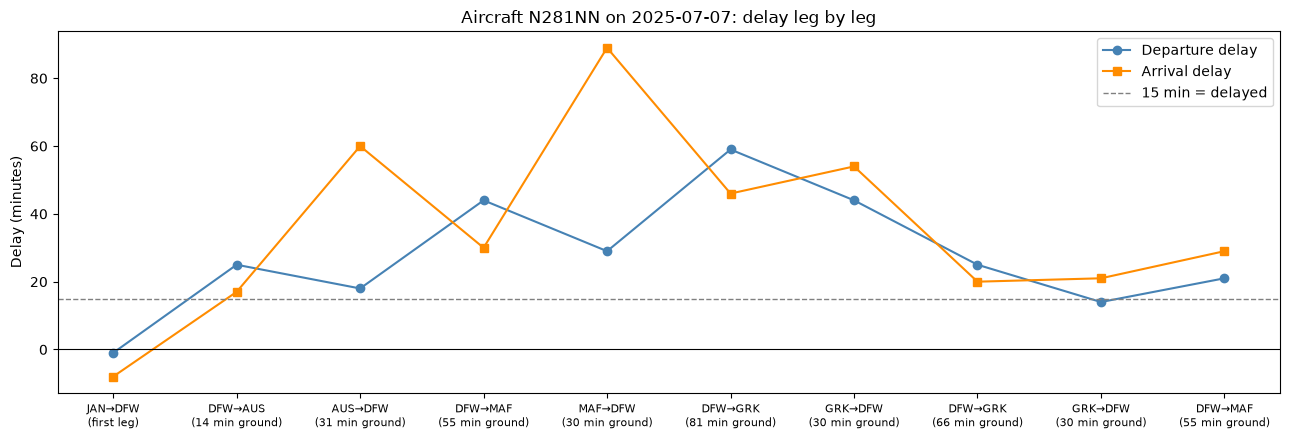

In [31]:
route = one["Origin"] + "→" + one["Dest"]
# Text under each point: the route, and the ground time before that leg (none for the first).
labels = [f"{route.iloc[0]}\n(first leg)"]
for r, ground in zip(route.iloc[1:], one["ground_before_min"].iloc[1:], strict=True):
    labels.append(f"{r}\n({ground:.0f} min ground)")
x = range(len(one))

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(x, one["DepDelay"], marker="o", color="steelblue", label="Departure delay")
ax.plot(x, one["ArrDelay"], marker="s", color="darkorange", label="Arrival delay")
ax.axhline(15, color="gray", linestyle="--", linewidth=1, label="15 min = delayed")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Delay (minutes)")
ax.set_title(f"Aircraft {TAIL} on {DAY.date()}: delay leg by leg")
ax.legend()
plt.tight_layout()
plt.show()

**Question:** Does the delay accumulate during the day? Find one place where a long ground time (buffer) absorbs part of the delay, and one leg where the delay grows between departure and arrival (the aircraft lands much later than it left). What could explain the second case?

**My answer:** yes delay might accumulate during the day . regardin the first one the example is dfw to grk and second example is maf to dfw

## 9. Ground-time distribution: where does a chain end?

**What:** for **every** aircraft, sort **all** its July legs by UTC departure (across days, not day by day) and pair each leg with the one before it.
One pair = one **link**. For each link, `ground_h` = this leg's scheduled departure − the previous leg's scheduled arrival, in hours.
It is only computed when the aircraft is where it should be (this leg's origin = the previous leg's destination).

**Why:** a delay passes from one leg to the next only when the ground time is short; an overnight stop usually absorbs it.
We need one number that separates "same chain" from "new chain": `chain_break_ground_time_hours`. It is chosen **from the data**, not fixed at 12 h.

- Only **scheduled** times are used: they are known in advance, so building chains this way leaks nothing.
- Airports are compared with the BTS **airport ID** (stable), not the 3-letter code (it can be renamed, e.g. PBI → DJT in 2026).
- **Limit: July only.** The first July leg of each aircraft has no previous leg here (it was flown in June), and its last July leg has no next leg.
  So about one link per aircraft is missing, mostly long ones. The full pipeline will use all months together.

In [32]:
# All legs that have a tail number, in flying order for each aircraft (whatever the day).
legs = df[has_tail].sort_values(["Tail_Number", "sched_dep_utc", "sched_arr_utc"])

# For each leg, fetch some values of the PREVIOUS leg of the same aircraft.
# groupby(...).shift(1) = "the row above, inside the same tail".
# The first leg of a tail has no row above: it gets a missing value.
PREV = {"DestAirportID": "prev_dest_id", "Dest": "prev_dest", "sched_arr_utc": "prev_arr_utc",
        "Cancelled": "prev_cancelled", "Diverted": "prev_diverted", "ArrDelay": "prev_arr_delay"}
previous = legs.groupby("Tail_Number")[list(PREV)].shift(1).rename(columns=PREV)
# Same rows as before, with the "prev_" columns added on the right.
legs = pd.concat([legs, previous], axis=1)

links = legs[legs["prev_arr_utc"].notna()].copy()      # a link needs a previous leg
links["same_airport"] = links["OriginAirportID"] == links["prev_dest_id"]
ground = (links["sched_dep_utc"] - links["prev_arr_utc"]).dt.total_seconds() / 3600
# A ground time has no meaning when the airports differ: keep it only for same-airport links.
links["ground_h"] = ground.where(links["same_airport"])

n_same = links["same_airport"].sum()
print(f"aircraft (tails): {legs['Tail_Number'].nunique():,} | legs: {len(legs):,} "
      f"| links: {len(links):,}")
print(f"links at the same airport: {n_same:,} ({100 * n_same / len(links):.1f} % of links)")

aircraft (tails): 5,671 | legs: 629,734 | links: 624,063
links at the same airport: 601,422 (96.4 % of links)


**What:** histogram of `ground_h` from 0 to 48 h (30-minute bins, **log scale** on the counts), and a zoom on the first 6 hours (10-minute bins, normal scale).
**Why:** we expect two groups: short turnarounds and overnight stops. The log scale is needed on the left because turnarounds are so many
that everything else would look flat. The threshold belongs in the emptiest zone between the two groups.

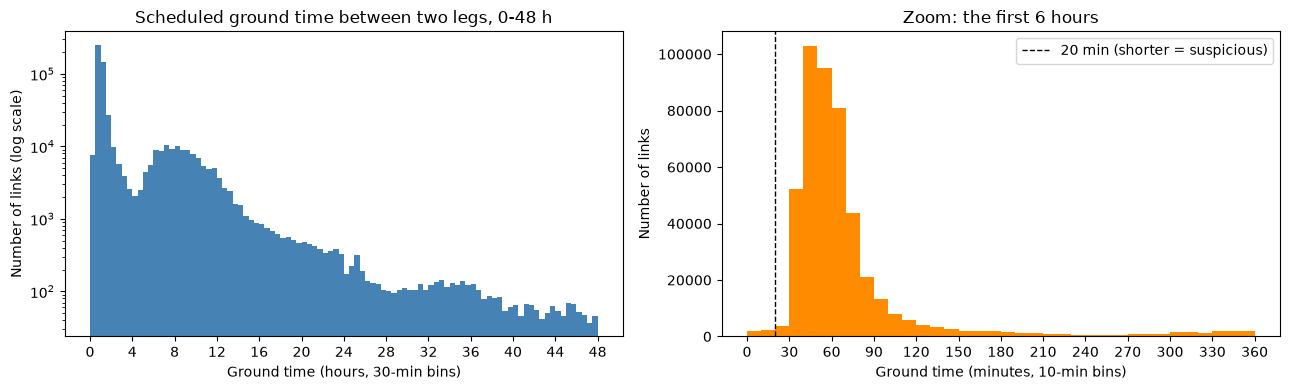

In [33]:
g = links["ground_h"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(g[(g >= 0) & (g <= 48)], bins=np.arange(0, 48.5, 0.5), color="steelblue", log=True)
axes[0].set_title("Scheduled ground time between two legs, 0-48 h")
axes[0].set_xlabel("Ground time (hours, 30-min bins)")
axes[0].set_ylabel("Number of links (log scale)")
axes[0].set_xticks(range(0, 49, 4))

# Whole minutes, so that every value falls cleanly into one 10-minute bin.
minutes = (g[(g >= 0) & (g <= 6)] * 60).round()
axes[1].hist(minutes, bins=np.arange(0, 361, 10), color="darkorange")
axes[1].axvline(20, color="black", linestyle="--", linewidth=1,
                label="20 min (shorter = suspicious)")
axes[1].set_title("Zoom: the first 6 hours")
axes[1].set_xlabel("Ground time (minutes, 10-min bins)")
axes[1].set_ylabel("Number of links")
axes[1].set_xticks(range(0, 361, 30))
axes[1].legend()
plt.tight_layout()
plt.show()

**What:** percentiles of `ground_h`, and counts of impossible or suspicious values: **negative** (the next leg is scheduled to leave
before the previous one arrives = the two legs overlap), **under 20 minutes** (too short to turn an aircraft around), and over 48 h.
**Why:** negative and very short values are not real turnarounds. One reason seen in the data: BTS records the tail number of the aircraft that
**really flew**, but we order legs by **scheduled** times; after an aircraft swap or a very long delay, the scheduled order no longer matches what happened.
Such links must be broken (section 10), never used as "previous leg".

In [34]:
MIN_GROUND_H = 20 / 60      # 20 minutes, written in hours

pct = g.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
pct.index = [f"p{q * 100:g}" for q in pct.index]

short = (g >= 0) & (g < MIN_GROUND_H)
print(f"links with a ground time: {len(g):,}")
print(f"  negative (overlap): {(g < 0).sum():,} ({100 * (g < 0).mean():.2f} %)")
print(f"  0 to 20 min:        {short.sum():,} ({100 * short.mean():.2f} %)")
print(f"  over 48 h:          {(g > 48).sum():,} ({100 * (g > 48).mean():.2f} %)")
pct.round(2).to_frame("ground time (hours)").T

links with a ground time: 601,422
  negative (overlap): 9,088 (1.51 %)
  0 to 20 min:        4,059 (0.67 %)
  over 48 h:          1,793 (0.30 %)


,p1,p5,p25,p50,p75,p90,p95,p99
ground time (hours),-0.38,0.5,0.75,1.07,2.58,9.45,11.93,25.28


**What:** find the emptiest 30-minute bin between the two groups (the "valley"), then print candidate thresholds around it with the share of links
each one would break (= links with a ground time above it). Then a wider table, from 2 h to 12 h.
**Why:** the valley is where the fewest links sit, so a threshold there has the fewest unclear cases on either side.
Around the valley the share barely changes from one candidate to the next: that is the sign of a real gap between two groups.

We look for the valley between 2 h and 8 h, i.e. between the two peaks seen on the left chart.

In [35]:
counts, edges = np.histogram(g, bins=np.arange(0, 48.5, 0.5))    # the same 30-min bins as the chart
starts = edges[:-1]                                               # left edge of each bin
between = (starts >= 2) & (starts < 8)                            # the zone between the two peaks
# argmin = position of the smallest count -> the start of the bin with the fewest links
valley_h = float(starts[between][counts[between].argmin()])
print(f"emptiest 30-min bin between 2 h and 8 h: {valley_h:g} to {valley_h + 0.5:g} h "
      f"({counts[between].min():,} links)")

CANDIDATES_H = [valley_h - 1, valley_h, valley_h + 1]
print("\ncandidate threshold -> share of same-airport links it would break (ground time > it)")
for t in CANDIDATES_H:
    print(f"  {t:g} h -> {100 * (g > t).mean():.1f} %  ({(g > t).sum():,} links)")

wider = pd.Series({t: 100 * (g > t).mean() for t in [2, 3, 4, 5, 6, 8, 10, 12]})
wider.index.name = "threshold (h)"
wider.round(1).to_frame("% of links broken").T

emptiest 30-min bin between 2 h and 8 h: 4 to 4.5 h (2,048 links)

candidate threshold -> share of same-airport links it would break (ground time > it)
  3 h -> 24.2 %  (145,642 links)
  4 h -> 23.2 %  (139,282 links)
  5 h -> 22.4 %  (134,653 links)


threshold (h),2,3,4,5,6,8,10,12
% of links broken,26.7,24.2,23.2,22.4,20.7,14.5,8.5,4.8


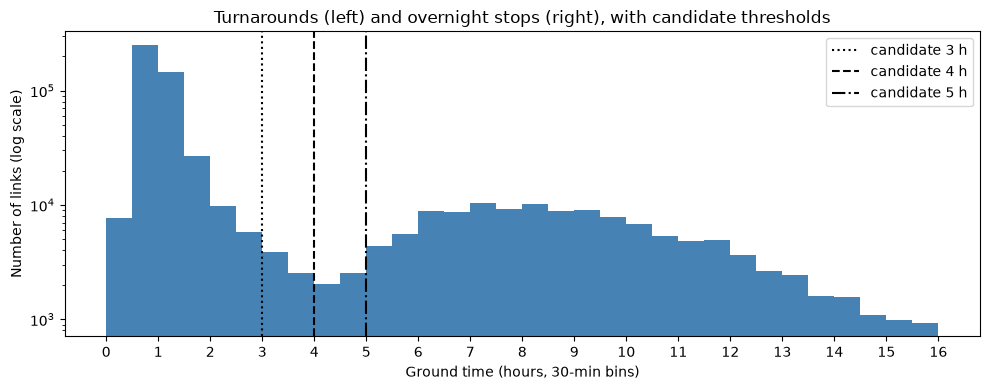

In [36]:
# The same histogram, 0-16 h, with the candidates drawn on it.
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(g[(g >= 0) & (g <= 16)], bins=np.arange(0, 16.5, 0.5), color="steelblue", log=True)
for t, style in zip(CANDIDATES_H, [":", "--", "-."], strict=True):   # one line style per candidate
    ax.axvline(t, color="black", linestyle=style, linewidth=1.5, label=f"candidate {t:g} h")
ax.set_title("Turnarounds (left) and overnight stops (right), with candidate thresholds")
ax.set_xlabel("Ground time (hours, 30-min bins)")
ax.set_ylabel("Number of links (log scale)")
ax.set_xticks(range(0, 17))
ax.legend()
plt.tight_layout()
plt.show()

**What (extra evidence, analysis only):** after a **late arrival** (previous leg ≥ 15 min late), how often does the next leg leave ≥ 15 min late,
depending on the ground time? Next to it: the same share for **all** links with that ground time (the normal level).
**Why:** the histogram shows where the two groups separate in the **schedule**. This chart shows where a delay **actually stops passing** to the next leg.
Where the two bars are close, a late arrival no longer changes anything: in practice the chain is over.

⚠️ This uses actual delays. It helps to choose the threshold; it is never a model input.

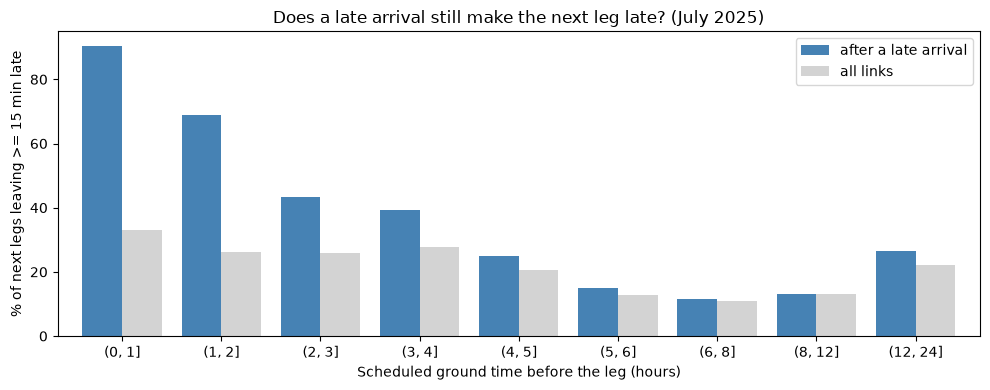

,links,links after a late arrival,after a late arrival,all links
ground_group,,,,
"(0, 1]",268850,61148,90.4,33.0
"(1, 2]",153889,36452,68.9,26.3
"(2, 3]",14533,5556,43.3,25.7
"(3, 4]",6131,2770,39.2,27.6
"(4, 5]",4454,1975,24.8,20.7
"(5, 6]",9904,4236,15.0,12.8
"(6, 8]",36704,15783,11.7,10.8
"(8, 12]",56502,23763,13.0,13.1
"(12, 24]",21711,8817,26.5,22.3


In [37]:
# Links at the same airport where both legs were really flown.
flown_pair = (links["same_airport"] & links["prev_cancelled"].eq(0) & links["prev_diverted"].eq(0)
              & links["Cancelled"].eq(0))
pairs = links[flown_pair].copy()
pairs["prev_late"] = pairs["prev_arr_delay"] >= 15
pairs["next_late"] = pairs["DepDelay"] >= 15
# pd.cut sorts each ground time into a group: (0, 1] = more than 0 h and up to 1 h, and so on.
pairs["ground_group"] = pd.cut(pairs["ground_h"], [0, 1, 2, 3, 4, 5, 6, 8, 12, 24])

by_group = pairs.groupby("ground_group", observed=True)
after_late = pairs[pairs["prev_late"]].groupby("ground_group", observed=True)
by_ground = pd.DataFrame({
    "links": by_group.size(),
    "links after a late arrival": after_late.size(),
    "after a late arrival": 100 * after_late["next_late"].mean(),     # % of next legs leaving late
    "all links": 100 * by_group["next_late"].mean(),
})

ax = by_ground[["after a late arrival", "all links"]].plot.bar(
    figsize=(10, 4), color=["steelblue", "lightgray"], width=0.8, rot=0)
ax.set_xlabel("Scheduled ground time before the leg (hours)")
ax.set_ylabel("% of next legs leaving >= 15 min late")
ax.set_title("Does a late arrival still make the next leg late? (July 2025)")
plt.tight_layout()
plt.show()
by_ground.round(1)

### Decision: yours

The code above only prints **candidates**. **Ahmed chooses the final value and writes it in `config.yaml`** (`chain_break_ground_time_hours`),
with one sentence of justification in `docs/learning_log.md` and in the decisions log of `CLAUDE.md`.

Things to weigh:
- **Lower threshold:** chains keep only real turnarounds, but you cut links where a late arrival still matters
  (in the last chart: ground-time groups above your threshold where the blue bar is still clearly higher than the grey one).
- **Higher threshold:** you keep those links, but chains start to include long daytime waits and short nights, where the previous leg says little
  (groups where blue and grey are almost equal).
- This is **July only**. Check the histogram again when all months are loaded (winter schedules may differ).

**Question:** Where do the two groups separate on the charts? Which threshold do you choose, and why? What would go wrong with a much lower value (2 h) or a much higher one (12 h)?

**My answer:**

## 10. Broken links: how many, and why?

**What:** apply the broken-chain rules (CLAUDE.md §5) to every link and count the links each rule breaks.
A link can break several rules at once, so the lines do not add up to the total.
**Why:** Golden rule 5: no silent drops. A broken link means "this leg starts a new chain": it gets no previous-leg features and is not a propagation example.
We must know how many links are broken, and for which reason.

`THRESHOLD_H` below is a **trial value** from section 9. Change it to see the effect. It does **not** change `config.yaml`.

| Rule | Why the link is broken |
|---|---|
| Airport mismatch | The aircraft is not where the previous leg ended: a leg is missing (international, ferry flight) or the data is wrong |
| Previous leg cancelled | The aircraft did not fly it, so there is no delay to inherit |
| Previous leg diverted | The aircraft landed at another airport |
| Ground time > threshold | Overnight stop or maintenance: a new chain starts |
| Ground time < 20 min or overlap | Not a real turnaround (aircraft swap or data error) |
| This leg cancelled | It has no delay, so it can never be a label |
| Missing tail number | No chain at all (counted on flights, not on links) |

Not counted here: "impossible **actual** timing" (an aircraft swap visible only in the actual times). It needs actual departures and arrivals in UTC and comes with the Silver step.

In [38]:
# >>> CHANGE ME <<<  Trial value: the middle candidate of section 9.
# To try another one, write a number instead, for example: THRESHOLD_H = 5.0
THRESHOLD_H = CANDIDATES_H[1]

# One True/False column per rule. Comparisons with a missing ground time (NaN) give False,
# so a link with an airport mismatch is counted by the first rule only.
rules = pd.DataFrame({
    "airport mismatch (Origin != previous Dest)": ~links["same_airport"],
    "previous leg cancelled": links["prev_cancelled"].eq(1),
    "previous leg diverted": links["prev_diverted"].eq(1),
    f"ground time > {THRESHOLD_H:g} h": links["ground_h"] > THRESHOLD_H,
    "ground time < 20 min or overlap (negative)": links["ground_h"] < MIN_GROUND_H,
    "this leg cancelled (no delay to predict)": links["Cancelled"].eq(1),
})
links["valid"] = ~rules.any(axis=1)        # valid = breaks no rule

table = rules.sum().to_frame("count")
table.loc["broken by at least one rule"] = (~links["valid"]).sum()
table.loc["VALID links"] = links["valid"].sum()
table["share (%)"] = (100 * table["count"] / len(links)).round(2)
table["share of"] = "links"
table.loc["missing tail number (no link possible)"] = [
    int((~has_tail).sum()), round(100 * (~has_tail).mean(), 2), "all flights"]

print(f"threshold tried: {THRESHOLD_H:g} h | links: {len(links):,} | flights: {len(df):,}")
table

threshold tried: 4 h | links: 624,063 | flights: 631,428


,count,share (%),share of
airport mismatch (Origin != previous Dest),22641,3.63,links
previous leg cancelled,13215,2.12,links
previous leg diverted,3086,0.49,links
ground time > 4 h,139282,22.32,links
ground time < 20 min or overlap (negative),13147,2.11,links
this leg cancelled (no delay to predict),13648,2.19,links
broken by at least one rule,184302,29.53,links
VALID links,439761,70.47,links
missing tail number (no link possible),1694,0.27,all flights


**Question:** Which rule breaks the most links? Is that a data problem or normal airline life? Why does a cancelled previous leg break the chain even when the airports match?

**My answer:**

## 11. Consistency check (analysis only, never a model input)

**What:** on the valid links, compare two things that should agree:
- the airline says this leg was late because of a **late aircraft** (`LateAircraftDelay > 0`);
- our chain says the previous leg of that aircraft **arrived late** (`ArrDelay > 0`).

Two shares:
1. Of the legs with `LateAircraftDelay > 0`, how many have a late previous arrival in **our** chain? → **the real check: it should be high.**
2. Of the legs whose previous leg arrived late, how many have `LateAircraftDelay > 0`? → naturally lower: the buffer absorbs many small delays,
   and BTS fills the cause columns only when the leg itself **arrives** ≥ 15 min late.

**Why:** our chains use only tail numbers and scheduled times. The cause column is an independent statement by the airline.
**A low share 1 would mean the chain logic is wrong** (our "previous leg" would often be the wrong flight) and must be fixed before going on.
For comparison, the same shares on the **broken** links: there we expect a weaker agreement.

⚠️ `LateAircraftDelay` and `ArrDelay` are known only after the flight: they are used here to check, never as model inputs.

In [39]:
def consistency(part: pd.DataFrame) -> pd.Series:
    """The two shares (in %) for a set of links."""
    late_aircraft = part["LateAircraftDelay"] > 0     # the airline's statement about THIS leg
    prev_late = part["prev_arr_delay"] > 0            # our chain: the previous leg arrived late
    # x[mask].mean() on True/False values = share of True among the rows kept by the mask
    share_1 = 100 * prev_late[late_aircraft].mean()
    share_2 = 100 * late_aircraft[prev_late].mean()
    # dtype=object keeps whole numbers as whole numbers in the display (no "439761.0")
    return pd.Series({
        "links": len(part),
        "legs with LateAircraftDelay > 0": int(late_aircraft.sum()),
        "1. of those, previous leg arrived late (%)": round(share_1, 1),
        "legs whose previous leg arrived late": int(prev_late.sum()),
        "2. of those, LateAircraftDelay > 0 (%)": round(share_2, 1),
    }, dtype=object)


pd.DataFrame({"valid links": consistency(links[links["valid"]]),
              "broken links": consistency(links[~links["valid"]])})

,valid links,broken links
links,439761,184302
legs with LateAircraftDelay > 0,77326,18977
"1. of those, previous leg arrived late (%)",97.0,39.7
legs whose previous leg arrived late,175737,92982
"2. of those, LateAircraftDelay > 0 (%)",42.7,8.1


**Question:** Why is share 1 the real check, and why is share 2 expected to be lower? What could explain a leg with `LateAircraftDelay > 0` whose previous leg in our chain arrived on time?

**My answer:**

---
## Summary of batch 2

What this notebook now contains, to reuse in `src/transform/to_utc.py`, `src/features/rotation.py` and the tests:
- **UTC:** `to_utc` / `to_utc_series` convert local clock times with time-zone **names** (`2400` = next day 00:00; Phoenix has no daylight saving time).
  Scheduled arrival = scheduled departure (UTC) + `CRSElapsedTime`, which avoids both the overnight-arrival and the destination-time-zone traps.
- **Time checks and flags (section 7):** `valid_hhmm` rejects impossible or malformed clock times (`1260`, `2500`, `""`, numbers);
  daylight-saving hours are never guessed (`NaT` + `dep_time_issue`); unusable durations give `NaT` + `duration_issue`;
  overnight = arrival **local date** > `FlightDate` (not the clock test); arrivals that disagree with `CRSArrTime` or the expected date
  keep their values and are flagged `sched_inconsistent` (a plausibility check, not a proof of the arrival date).
  These rows are **flagged only**: whether and how they are excluded from chains and labels is a Silver decision, not applied in sections 8–11.
- **One aircraft, one day:** delay travels from leg to leg; the scheduled ground time (buffer) decides how much of it is passed on.
- **Links:** every aircraft's legs sorted by scheduled UTC departure across days; scheduled ground time for each link; two groups (turnarounds, overnight stops) with a valley between them.
- **Broken links:** counted rule by rule, nothing dropped silently.
- **Consistency check:** the airline's "late aircraft" cause compared with our own chains.

**Still to do (Ahmed):**
1. Choose `chain_break_ground_time_hours`, write it in `config.yaml`, and note the reason (learning log + decisions log).
2. Put `THRESHOLD_H` to that value in section 10 and rerun sections 10–11.

**Limits to remember:** one month only (links across the June/August borders are missing); legs are ordered by **scheduled** time, so aircraft swaps show up
as overlaps or airport mismatches; the swap check on actual times is left for the Silver step, which also applies the flag policy of section 7 (`dep_time_issue`, `sched_inconsistent`).

### Check questions of step 1.2 (CLAUDE.md): answer without notes

**Question:** Why do delays grow later in the day? (Use what you saw in sections 5, 8 and 9.)

**My answer:**

**Question:** What share of delay minutes is "late aircraft"? (Section 6.) What does section 11 add to that number?

**My answer:**

---
*End of notebook 01.*